# Import Packages

In [1]:
using DifferentialEquations
using OrdinaryDiffEq
using DiffEqBase
using Sundials
using ODEInterfaceDiffEq
using Plots
using Measures
using CSV
using DataFrames
using EasyFit
using StatsPlots
using LinearAlgebra
using Random
using Distributions
using OrdinaryDiffEq
Random.seed!(145975);
using KernelDensity
using LaTeXStrings
using StatsBase
using JLD2
using HypothesisTests
using LaTeXStrings
using Trapz
using DataFrames, GLM, StatsBase


In [2]:
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\BayesianInference\\FunctionsBayesInfs.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\InitalParameterFitPriorDef\\ModelFunctionsAll.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\FunctionsBayesOED.jl")

redSamples (generic function with 2 methods)

# Load Posteriors

In [3]:
poster1 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_Init_Try1.csv", DataFrame));

posterR2 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_Ran1c_Try1c.csv", DataFrame));
posterI2 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_ID1_Try1.csv", DataFrame));
posterO2 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_OED1_Try1.csv", DataFrame));

posterR3 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_Ran2d_Try1.csv", DataFrame));
posterI3 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_ID2b_Try1.csv", DataFrame));
posterO3 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_OED2_Try1.csv", DataFrame));

posterR3b = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_Ran2g_Try1.csv", DataFrame));
posterO3b = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_OED2b_Try1.csv", DataFrame));

posterO4 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_OED3_Try2.csv",DataFrame));

posterO5 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_OED3_Try2.csv",DataFrame));


In [4]:
poster1Cut = hcat(poster1[:,1], poster1[:,3:12], poster1[:,14:end]);

posterR2Cut = hcat(posterR2[:,1], posterR2[:,3:12], posterR2[:,14:end]);
posterI2Cut = hcat(posterI2[:,1], posterI2[:,3:12], posterI2[:,14:end]);
posterO2Cut = hcat(posterO2[:,1], posterO2[:,3:12], posterO2[:,14:end]);

posterR3Cut = hcat(posterR3[:,1], posterR3[:,3:12], posterR3[:,14:end]);
posterI3Cut = hcat(posterI3[:,1], posterI3[:,3:12], posterI3[:,14:end]);
posterO3Cut = hcat(posterO3[:,1], posterO3[:,3:12], posterO3[:,14:end]);

posterR3bCut = hcat(posterR3b[:,1], posterR3b[:,3:12], posterR3b[:,14:end]);
posterO3bCut = hcat(posterO3b[:,1], posterO3b[:,3:12], posterO3b[:,14:end]);

posterO4Cut = hcat(posterO4[:,1], posterO4[:,3:12], posterO4[:,14:end]);

posterO5Cut = hcat(posterO5[:,1], posterO5[:,3:12], posterO5[:,14:end]);


In [5]:
Pris = [Normal(40.92, 10), Normal(0.0055, 0.0055), Normal(0.0275, 0.0275), Normal(0.045, 0.045), Normal(0.45, 0.45), Normal(0.95, 0.95), Normal(0.95, 0.95), 
        Normal(0.95, 0.95), Normal(0.0085, 0.0085), Normal(0.95, 0.95), Normal(0.0029, 0.0029), Normal(650, 260), Normal(16000, 6400), Normal(550, 275)];

namess = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_a",L"NADH_0",L"NAD+_0",L"LDH_0"];

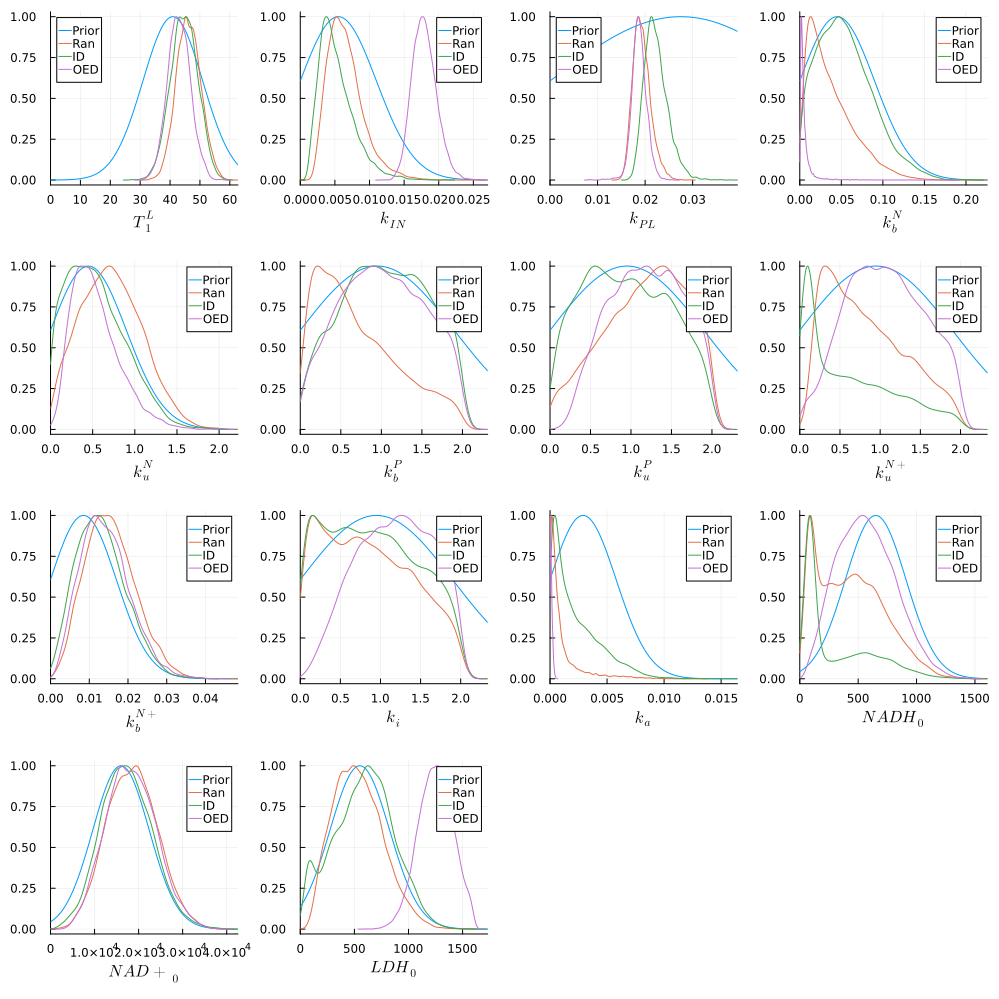

In [6]:
postss = Array{Any}(undef, length(Pris))

for i in 1:length(Pris)
    rr1 = kde(posterR2Cut[:,i])
    rr2 = kde(posterI2Cut[:,i])
    rr3 = kde(posterO2Cut[:,i])

    x = range(0,maximum(vcat(rr1.x, rr2.x, rr3.x)), length=100)
    y = pdf.(Pris[i], x)

    ppt1 = plot(x, y./maximum(y), label = "Prior", xlabel = namess[i])
    plot!(rr1.x, rr1.density/maximum(rr1.density), label = "Ran")
    plot!(rr2.x, rr2.density/maximum(rr2.density), label = "ID")
    plot!(rr3.x, rr3.density/maximum(rr3.density), label = "OED", xlim = [0,maximum(vcat(rr1.x, rr2.x, rr3.x))])

    postss[i] = ppt1
end

plot(postss..., size = (1000,1000))

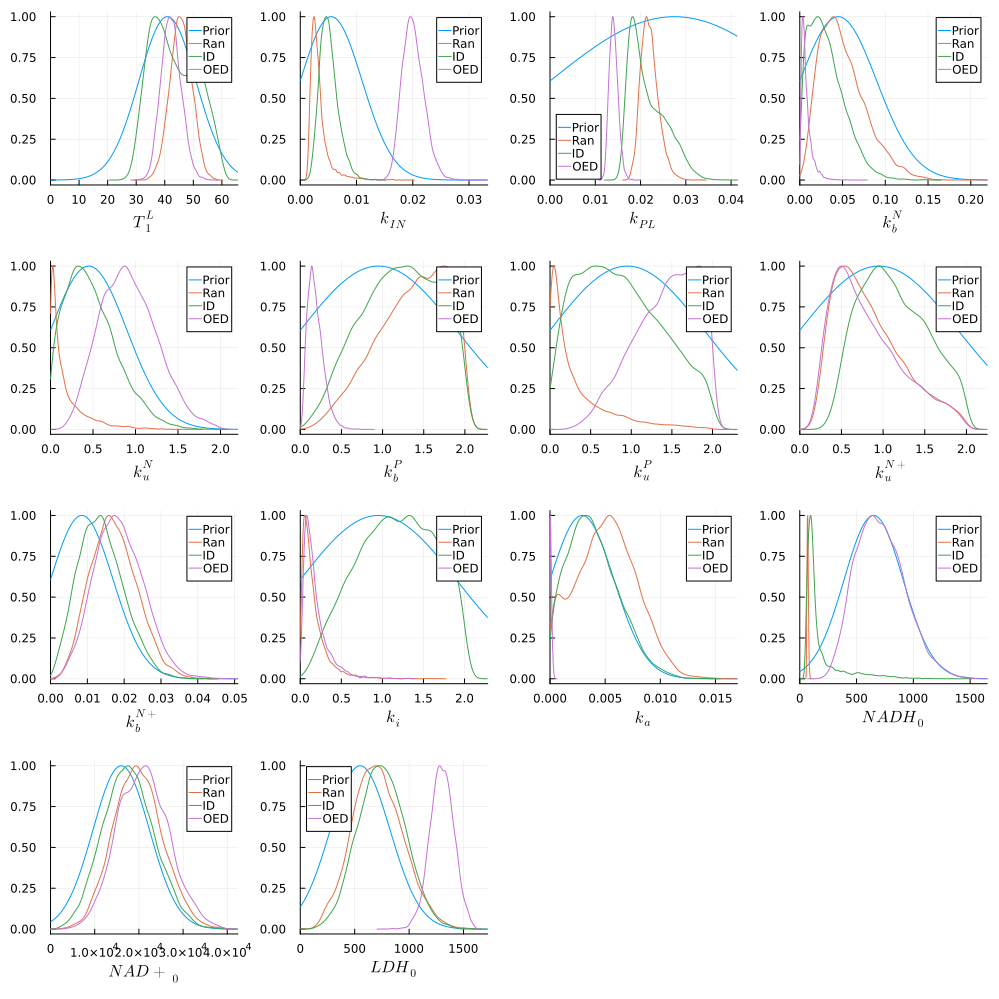

In [219]:
postss = Array{Any}(undef, length(Pris))

for i in 1:length(Pris)
    rr1 = kde(posterR3Cut[:,i])
    rr2 = kde(posterI3Cut[:,i])
    rr3 = kde(posterO3Cut[:,i])

    x = range(0,maximum(vcat(rr1.x, rr2.x, rr3.x)), length=100)
    y = pdf.(Pris[i], x)

    ppt1 = plot(x, y./maximum(y), label = "Prior", xlabel = namess[i])
    plot!(rr1.x, rr1.density/maximum(rr1.density), label = "Ran")
    plot!(rr2.x, rr2.density/maximum(rr2.density), label = "ID")
    plot!(rr3.x, rr3.density/maximum(rr3.density), label = "OED", xlim = [0,maximum(vcat(rr1.x, rr2.x, rr3.x))])

    postss[i] = ppt1
end

plot(postss..., size = (1000,1000))

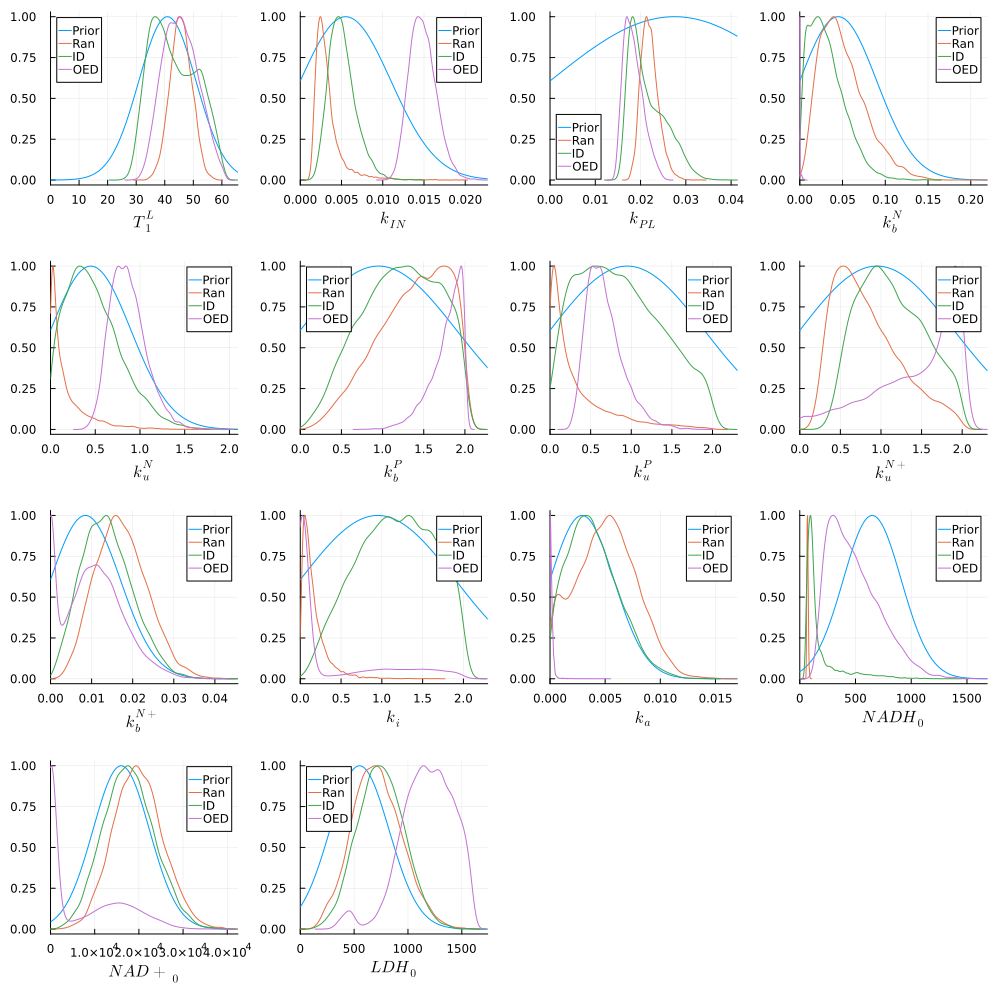

In [7]:
postss = Array{Any}(undef, length(Pris))

for i in 1:length(Pris)
    rr1 = kde(posterR3Cut[:,i])
    rr2 = kde(posterI3Cut[:,i])
    rr3 = kde(posterO4Cut[:,i])

    x = range(0,maximum(vcat(rr1.x, rr2.x, rr3.x)), length=100)
    y = pdf.(Pris[i], x)

    ppt1 = plot(x, y./maximum(y), label = "Prior", xlabel = namess[i])
    plot!(rr1.x, rr1.density/maximum(rr1.density), label = "Ran")
    plot!(rr2.x, rr2.density/maximum(rr2.density), label = "ID")
    plot!(rr3.x, rr3.density/maximum(rr3.density), label = "OED", xlim = [0,maximum(vcat(rr1.x, rr2.x, rr3.x))])

    postss[i] = ppt1
end

plot(postss..., size = (1000,1000))

# Pyruvate Concentrations

In [6]:
ranP = [3.2, 18, 6];
ranPb = [3.2, 18, 13.1];
# ranP = [3.2, 29.6, 18];
idP  = [3.2, 12.8, 25.6];
oedP = [3.2, 0.6, 8.3];
oedPb = [3.2, 0.6, 40];

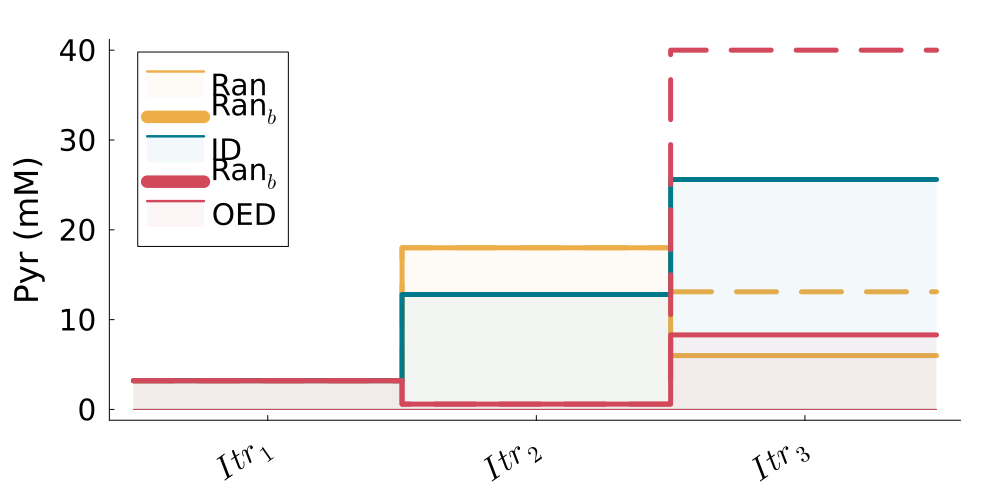

In [7]:
ppr = plot(vcat(collect(0:0.01:1-0.01), collect(1:0.01:2-0.01), collect(2:0.01:3-0.01)), 
        vcat(repeat([ranP[1]], 100), repeat([ranP[2]], 100), repeat([ranP[3]], 100)), linetype=:step, label = "",
        xticks = ([0.5,1.5,2.5], [L"Itr_1",L"Itr_2",L"Itr_3"]), grid = false, linewidth = 5, #yrange = (0,40),
        ylabel = "Pyr (mM)", margin=8Plots.mm,xtickfont=font(22), ytickfont=font(20), guidefont=font(22), titlefont=font(22),
        xrotation = 35, size = (1000,400), colour = "#edae49")
    
    plot!(vcat(collect(0:0.01:1-0.01), collect(1:0.01:2-0.01), collect(2:0.01:3-0.01)), zeros(300), fillrange = vcat(repeat([ranP[1]], 100), repeat([ranP[2]], 100), repeat([ranP[3]], 100)), 
            fillalpha=0.05, label = "Ran", colour = "#edae49")


# -----------------------------------------------------------------------------------------------------------------------------------
    plot!(vcat(collect(0:0.01:1-0.01), collect(1:0.01:2-0.01), collect(2:0.01:3-0.01)), linestyle=:dash, 
        vcat(repeat([ranPb[1]], 100), repeat([ranPb[2]], 100), repeat([ranPb[3]], 100)), linetype=:step, label = "Ran"*L"_b",
        linewidth = 5, colour = "#edae49")
# -----------------------------------------------------------------------------------------------------------------------------------


    plot!(vcat(collect(0:0.01:1-0.01), collect(1:0.01:2-0.01), collect(2:0.01:3-0.01)), 
        vcat(repeat([idP[1]], 100), repeat([idP[2]], 100), repeat([idP[3]], 100)), linetype=:step, label = "", 
        xticks = ([0.5,1.5,2.5], [L"Itr_1",L"Itr_2",L"Itr_3"]), grid = false, linewidth = 5, #yrange = (0,40),
        ylabel = "Pyr (mM)", margin=8Plots.mm,xtickfont=font(22), ytickfont=font(20), guidefont=font(22), titlefont=font(22),
        xrotation = 35, size = (1000,400), colour = "#00798cff")
    
    plot!(vcat(collect(0:0.01:1-0.01), collect(1:0.01:2-0.01), collect(2:0.01:3-0.01)), zeros(300), fillrange = vcat(repeat([idP[1]], 100), repeat([idP[2]], 100), repeat([idP[3]], 100)), 
            fillalpha=0.05, label = "ID", colour = "#00798cff")



    # -----------------------------------------------------------------------------------------------------------------------------------
    plot!(vcat(collect(0:0.01:1-0.01), collect(1:0.01:2-0.01), collect(2:0.01:3-0.01)), linestyle=:dash, 
        vcat(repeat([oedPb[1]], 100), repeat([oedPb[2]], 100), repeat([oedPb[3]], 100)), linetype=:step, label = "Ran"*L"_b",
        linewidth = 5, colour = "#d1495bff")
    # -----------------------------------------------------------------------------------------------------------------------------------

    plot!(vcat(collect(0:0.01:1-0.01), collect(1:0.01:2-0.01), collect(2:0.01:3-0.01)), 
        vcat(repeat([oedP[1]], 100), repeat([oedP[2]], 100), repeat([oedP[3]], 100)), linetype=:step, label = "",
        xticks = ([0.5,1.5,2.5], [L"Itr_1",L"Itr_2",L"Itr_3"]), grid = false, linewidth = 5, #yrange = (0,30),
        ylabel = "Pyr (mM)", margin=8Plots.mm,xtickfont=font(22), ytickfont=font(20), guidefont=font(22), titlefont=font(22),
        xrotation = 35, size = (1000,500), colour = "#d1495bff")
    
    plot!(vcat(collect(0:0.01:1-0.01), collect(1:0.01:2-0.01), collect(2:0.01:3-0.01)), zeros(300), fillrange = vcat(repeat([oedP[1]], 100), repeat([oedP[2]], 100), repeat([oedP[3]], 100)), 
            fillalpha=0.05, label = "OED", colour = "#d1495bff", legendfontsize=20,legend=:topleft)

# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure5Stuff\\InputDesignProfiles.svg")

display(ppr)

# Utility Function Value

In [8]:
# ranU = [349.1749112520019,160.65632135935536,24.63998703915345];
ranU = [349.1749112520019,164.41130796489722,87.52892698583814];
ranUb = [NaN,NaN,45.93102344028731];
iddU = [349.1749112520019,165.60299862073333,72.35064718442467];
oedU = [349.1749112520019,323.90686425576286,111.67968891669209];
oedUb = [NaN,NaN,96.4165555207867];

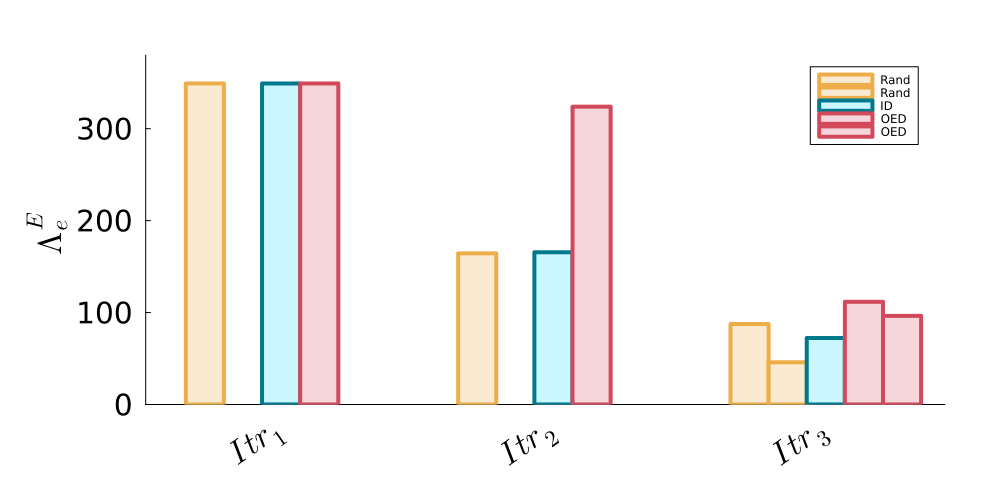

In [10]:
ppr = groupedbar(abs.([ranU ranUb iddU oedU oedUb]) , bar_position = :dodge, bar_width=0.7, label = ["Rand" "Rand" "ID" "OED" "OED"], colour = ["#faead1ff" "#faead1ff" "#caf7ffff" "#f5d6daff" "#f5d6daff"], 
linecolor = ["#edae49" "#edae49" "#00798cff" "#d1495bff" "#d1495bff"], linewidth = 4,
xticks = (1:3, [L"Itr_1", L"Itr_2", L"Itr_3"]), 
        # ylabel = "Prediction \nUncertainty "*L"$\Lambda^E_e$",
        ylabel = L"$\Lambda^E_e$", 
        grid = false, margin=12Plots.mm,xtickfont=font(22), ytickfont=font(20), guidefont=font(22), titlefont=font(22),
        xrotation = 35, size = (1000,500), ylim = (0, 380))

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure5Stuff\\InputDesignUtility2.svg")

display(ppr)

# Entropy vs Covariance

In [9]:
Covs = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\ResultsPostAnal\\CovMods.jld")
Ents = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\EntroPosters.jld")

Dict{String, Any} with 4 entries:
  "HPrior"   => 19.2311
  "H_Post"   => Any[0.251703 0.251703 … 0.251703 0.251703; -6.49829 -6.49829 … …
  "H_L_Post" => Any[-1.8626 -1.8626 … -1.8626 -1.8626; -8.53465 -8.53465 … -13.…
  "H_U_Post" => Any[11.5929 11.5929 … 11.5929 11.5929; 4.92641 4.92641 … -0.267…

In [10]:
ranC = -Covs["CovsR"];
ranCb = -Covs["CovsRb"];
iddC = -Covs["CovsI"];
oedC = -Covs["CovsO"];
oedCb = -Covs["CovsOb"];

ranE = Ents["HPrior"] .- Ents["H_Post"][:,1];
ranEb = Ents["HPrior"] .- Ents["H_Post"][:,2];
iddE = Ents["HPrior"] .- Ents["H_Post"][:,3];
oedE = Ents["HPrior"] .- Ents["H_Post"][:,4];
oedEb = Ents["HPrior"] .- Ents["H_Post"][:,5];

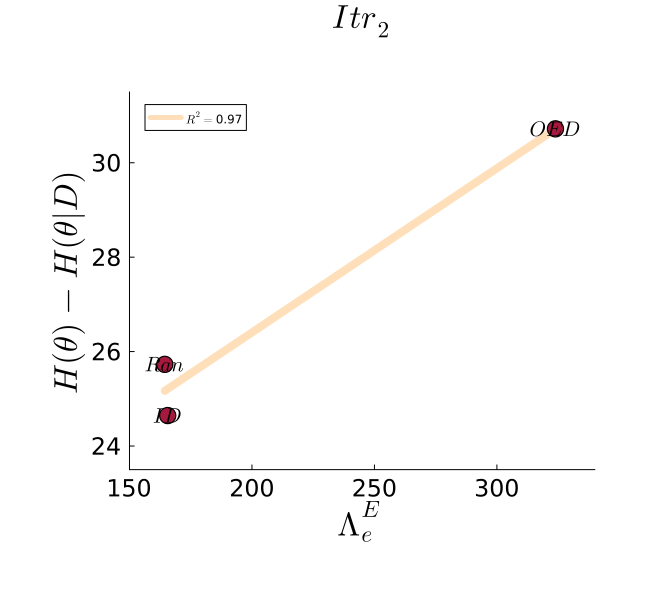

In [25]:
xx = [ranU[2],iddU[2],oedU[2]]
yy = [ranE[2],iddE[2],oedE[2]]
data = DataFrame(X=xx, Y=yy)
ols = lm(@formula(Y ~ X), data)

pps1 = plot(minimum(xx):maximum(xx), predict(ols, DataFrame(X = minimum(xx):maximum(xx))), label = L"R^2 = "*string(round(r2(ols), digits=3)), linewidth=8, colour="#FFDFB9")
scatter!(xx, yy, grid = false, label = "", title = L"Itr_2", xlabel = L"$\Lambda^E_e$", ylabel = L"H(\theta) - H(\theta | D)",
        margin=12Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(22), titlefont=font(22), markersize=9, colour="#A4193D", 
        # xlim = (150, 340), ylim = (23.5,31.5),size = (650,500))
        xlim = (150, 340), ylim = (23.5,31.5),size = (650,600))


annotate!(xx[1], yy[1], L"Ran", 14)
annotate!(xx[2], yy[2], L"ID", 14)
annotate!(xx[3], yy[3], L"OED", 14)

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure5Stuff\\UncertainVsEntro2.svg")

display(pps1)

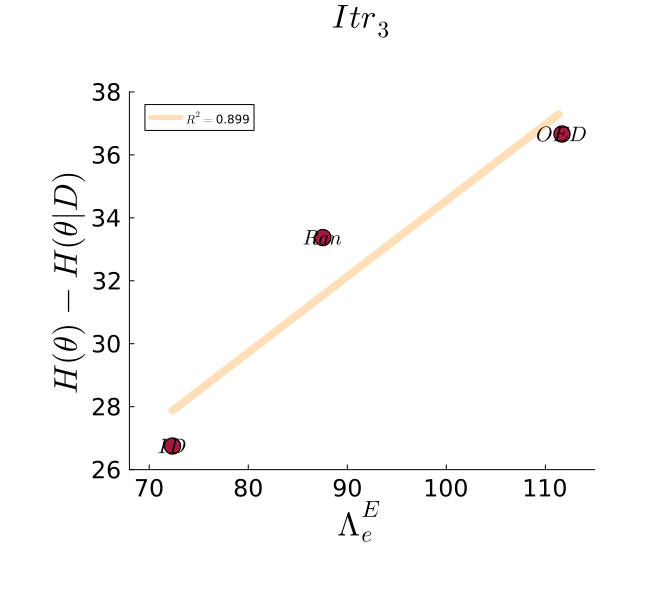

In [24]:
xx = [ranU[3],iddU[3],oedU[3]]
yy = [ranE[3],iddE[3],oedE[3]]
data = DataFrame(X=xx, Y=yy)
ols = lm(@formula(Y ~ X), data)

pps1= plot(minimum(xx):maximum(xx), predict(ols, DataFrame(X = minimum(xx):maximum(xx))), label = L"R^2 = "*string(round(r2(ols), digits=3)), linewidth=8, colour="#FFDFB9")
scatter!(xx, yy, grid = false, label = "", title = L"Itr_3", xlabel = L"$\Lambda^E_e$", ylabel = L"H(\theta) - H(\theta | D)",
        margin=12Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(22), titlefont=font(22), markersize=9, colour="#A4193D",
        # xlim=(68,115), ylim=(26,38),size = (650,500))
        xlim=(68,115), ylim=(26,38),size = (650,600))

annotate!(xx[1], yy[1], L"Ran", 14)
annotate!(xx[2], yy[2], L"ID", 14)
annotate!(xx[3], yy[3], L"OED", 14)

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure5Stuff\\UncertainVsEntro3.svg")

display(pps1)

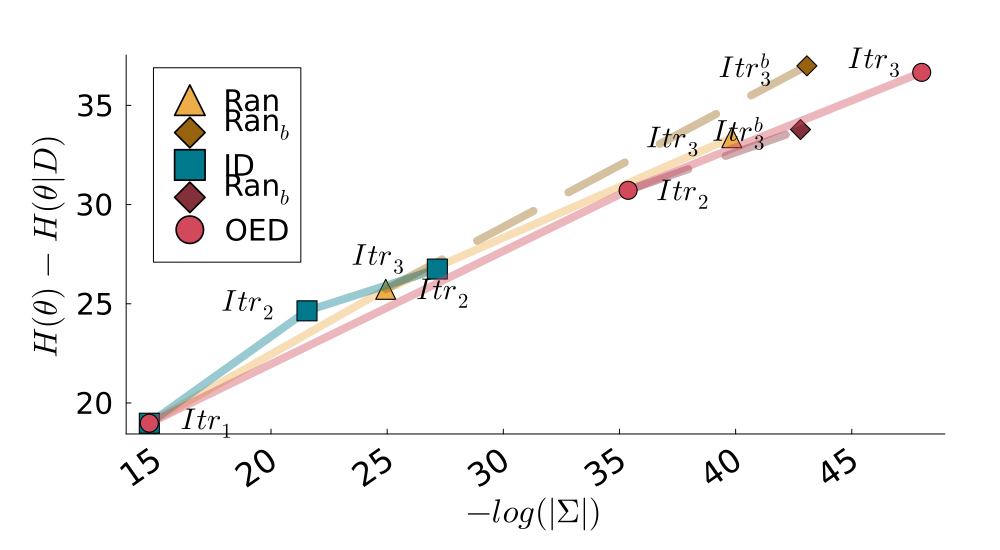

In [23]:
ppr = plot(ranC, ranE, label = "", grid = false, xlabel = L"-log(|\Sigma|)", ylabel = L"H(\theta) - H(\theta | D)", colour = "#edae49", linewidth = 8, alpha = 0.4)
        scatter!(ranC, ranE, label = "Ran", markershape=:utriangle, colour = "#edae49", markersize = 10, margin=12Plots.mm,xtickfont=font(22), 
        ytickfont=font(20), guidefont=font(22), titlefont=font(22),
        # xrotation = 35, size = (1000,650))
        xrotation = 35, size = (1000,550))
        annotate!(ranC[1]+2.5, ranE[1]+0, L"Itr_1", 20)
        annotate!(ranC[2]+2.5, ranE[2]-0.2, L"Itr_2", 20)
        annotate!(ranC[3]-2.5, ranE[3]-0.2, L"Itr_3", 20)

        plot!(ranCb[2:end], ranEb[2:end], label = "",colour = "#97630fff", linewidth = 8, alpha = 0.4, linestyle =:dash)
        scatter!([ranCb[3]], [ranEb[3]], label = "Ran"*L"_b", markershape=:diamond, colour = "#97630fff", markersize = 10)
        annotate!(ranCb[3]-2.5, ranEb[3]-0.2, L"Itr_{3}^b", 20)


        plot!(iddC, iddE, label = "", grid = false, xlabel = L"-log(|\Sigma|)", ylabel = L"H(\theta) - H(\theta | D)", colour = "#00798cff", linewidth = 8, alpha = 0.4)
        scatter!(iddC, iddE, label = "ID", markershape=:square, colour = "#00798cff", markersize = 10, margin=12Plots.mm,xtickfont=font(22), 
        ytickfont=font(20), guidefont=font(22), titlefont=font(22),
        xrotation = 35)
        # annotate!(iddC[1]+0.2, iddE[1], L"Exp_1", 12)
        annotate!(iddC[2]-2.5, iddE[2]+0.3, L"Itr_2", 20)
        annotate!(iddC[3]-2.5, iddE[3]+0.5, L"Itr_3", 20)



        plot!(oedCb[2:end], oedEb[2:end], label = "",colour = "#84303bff", linewidth = 8, alpha = 0.4, linestyle =:dash)
        scatter!([oedCb[3]], [oedEb[3]], label = "Ran"*L"_b", markershape=:diamond, colour = "#84303bff", markersize = 10)
        annotate!(oedCb[3]-2.5, oedEb[3]-0.2, L"Itr_{3}^b", 20)

        
        plot!(oedC, oedE, label = "", grid = false, xlabel = L"-log(|\Sigma|)", ylabel = L"H(\theta) - H(\theta | D)", colour = "#d1495bff", linewidth = 8, alpha = 0.4)
        scatter!(oedC, oedE, label = "OED", markershape=:circle, colour = "#d1495bff", markersize = 10, margin=12Plots.mm,xtickfont=font(22), 
        ytickfont=font(20), guidefont=font(22), titlefont=font(22),
        xrotation = 35, legendfontsize=20)
        # annotate!(oedC[1]+0.2, oedE[1], L"Exp_1", 12)
        annotate!(oedC[2]+2.4, oedE[2]-0.2, L"Itr_2", 20)
        annotate!(oedC[3]-2, oedE[3]+0.5, L"Itr_3", 20)

        
savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure5Stuff\\EntropyCov.svg")

display(ppr)

# Select best and worst parameter inference

In [11]:
namess = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_a",L"NADH_0",L"NAD+_0",L"LDH_0"];

In [12]:
mes = [40.92, 0.0055, 0.0275, 0.045, 0.45, 0.95, 0.95, 0.95, 0.0085, 0.95, 0.0029, 650, 16000, 550];
sts = [10, 0.0055, 0.0275, 0.045, 0.45, 0.95, 0.95, 0.95, 0.0085, 0.95, 0.0029, 260, 6400, 275];

Random.seed!(564654)
prismps = [rand(Truncated(Normal(mes[i], sts[i]), 0, mes[i]+4*sts[i]), 8000) for i in 1:length(mes)];

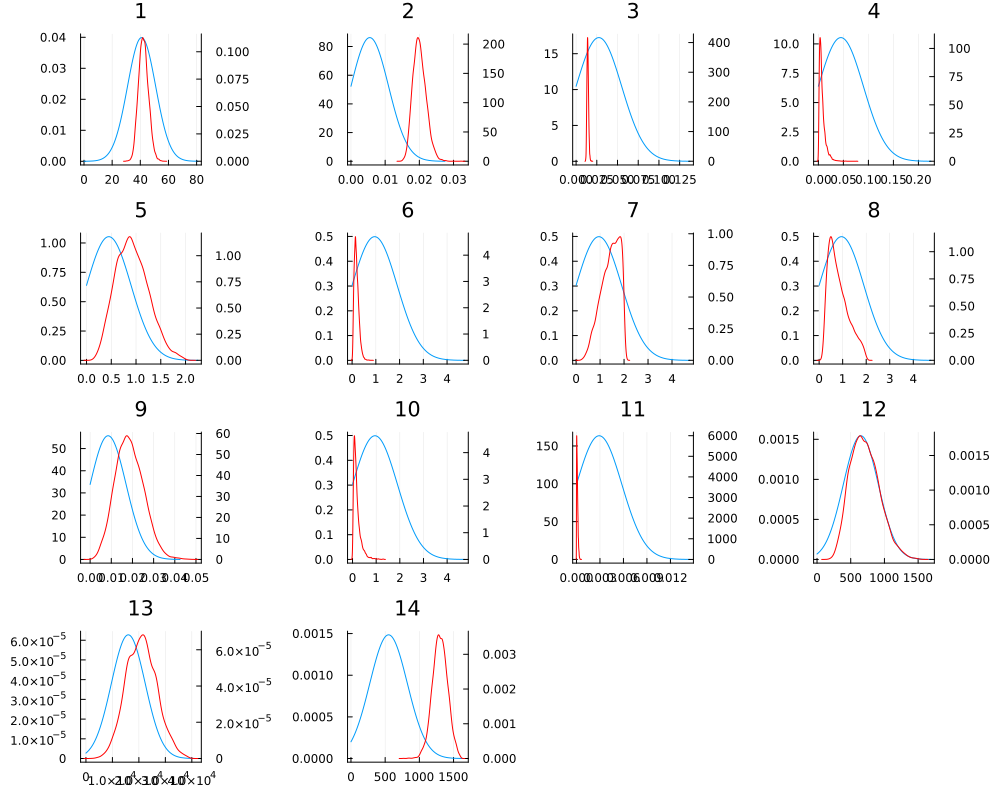

In [13]:
posts = [posterO3Cut, posterR3Cut, posterI3Cut, posterR3bCut, posterO3bCut];
astInf = [8,1]

pst = Array{Any}(undef, 14)

for i in 1:14
    astInf = [i,1]
    pst[i]=plot(Truncated(Normal(mes[astInf[1]], sts[astInf[1]]), 0, mes[astInf[1]]+4*sts[astInf[1]]), label = "", title = string(i))
    plot!(twinx(), kde(posts[astInf[2]][:,astInf[1]]), label="", colour = "red")
end
plot(pst..., size = (1000,800))

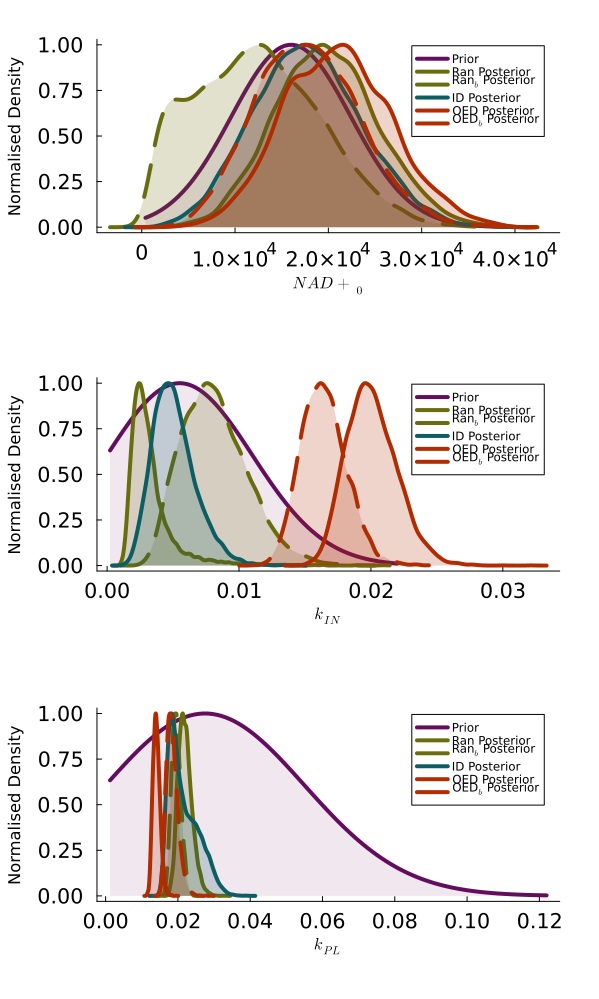

In [29]:
bst = 3
wst = 13#12
med = 2


# Worst
x = range(0, 40000, length=100)
y = pdf.(Truncated(Normal(mes[wst], sts[wst]), 0, 40000), x)
ix = abs.(x) .> 1

pp1 = plot(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#640D5F", linewidth=0, label = "", alpha = 0.1, xlabel = namess[wst], ylabel = "Normalised Density", margins=8Plots.mm)
plot!(x[ix], y[ix]./maximum(y), label = "Prior", grid = false, linewidth = 4, colour = "#640D5F")

x = kde(posts[2][:,wst]).x
y = kde(posts[2][:,wst]).density
ix = abs.(x) .> 0
plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#6a6d0dff", linewidth=0, label = "", alpha = 0.2, ylabel = "Normalised Density")
plot!(x, y./maximum(y), label="Ran Posterior", linewidth = 4, colour = "#6a6d0dff")


x = kde(posts[4][:,wst]).x
y = kde(posts[4][:,wst]).density
ix = abs.(x) .> 0
plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#6a6d0dff", linewidth=0, label = "", alpha = 0.2, ylabel = "Normalised Density")
plot!(x, y./maximum(y), label="Ran"*L"_b"*" Posterior", linewidth = 4, colour = "#6a6d0dff", linestyle=:dash)


x = kde(posts[3][:,wst]).x
y = kde(posts[3][:,wst]).density
ix = abs.(x) .> 0
plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#0d5e64ff", linewidth=0, label = "", alpha = 0.2, ylabel = "Normalised Density")
plot!(x, y./maximum(y), label="ID Posterior", linewidth = 4, colour = "#0d5e64ff")


x = kde(posts[1][:,wst]).x
y = kde(posts[1][:,wst]).density
ix = abs.(x) .> 0
plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#B12C00", linewidth=0, label = "", alpha = 0.2, ylabel = "Normalised Density")
plot!(x, y./maximum(y), label="OED Posterior", linewidth = 4, colour = "#B12C00")

x = kde(posts[5][:,wst]).x
y = kde(posts[5][:,wst]).density
ix = abs.(x) .> 0
plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#B12C00", linewidth=0, label = "", alpha = 0.2, ylabel = "Normalised Density")
plot!(x, y./maximum(y), label="OED"*L"_b"*" Posterior", linewidth = 4, colour = "#B12C00", linestyle=:dash)



# Medium
x = range(0, 0.022, length=100)
y = pdf.(Truncated(Normal(mes[med], sts[med]), 0, 0.022), x)
ix = abs.(x) .> 0

pp2 = plot(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#640D5F", linewidth=0, label = "", alpha = 0.1, xlabel = namess[med], ylabel = "Normalised Density", margins=8Plots.mm)
plot!(x[ix], y[ix]./maximum(y), label = "Prior", grid = false, linewidth = 4, colour = "#640D5F")

x = kde(posts[2][:,med]).x
y = kde(posts[2][:,med]).density
ix = abs.(x) .> 0
plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#6a6d0dff", linewidth=0, label = "", alpha = 0.2, ylabel = "Normalised Density")
plot!(x, y./maximum(y), label="Ran Posterior", linewidth = 4, colour = "#6a6d0dff")

x = kde(posts[4][:,med]).x
y = kde(posts[4][:,med]).density
ix = abs.(x) .> 0
plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#6a6d0dff", linewidth=0, label = "", alpha = 0.2, ylabel = "Normalised Density")
plot!(x, y./maximum(y), label="Ran"*L"_b"*" Posterior", linewidth = 4, colour = "#6a6d0dff", linestyle=:dash)


x = kde(posts[3][:,med]).x
y = kde(posts[3][:,med]).density
ix = abs.(x) .> 0
plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#0d5e64ff", linewidth=0, label = "", alpha = 0.2, ylabel = "Normalised Density")
plot!(x, y./maximum(y), label="ID Posterior", linewidth = 4, colour = "#0d5e64ff")


x = kde(posts[1][:,med]).x
y = kde(posts[1][:,med]).density
ix = abs.(x) .> 0
plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#B12C00", linewidth=0, label = "", alpha = 0.2, ylabel = "Normalised Density")
plot!(x, y./maximum(y), label="OED Posterior", linewidth = 4, colour = "#B12C00")

x = kde(posts[5][:,med]).x
y = kde(posts[5][:,med]).density
ix = abs.(x) .> 0
plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#B12C00", linewidth=0, label = "", alpha = 0.2, ylabel = "Normalised Density")
plot!(x, y./maximum(y), label="OED"*L"_b"*" Posterior", linewidth = 4, colour = "#B12C00", linestyle=:dash)




# Best
x = range(0, 0.122, length=100)
y = pdf.(Truncated(Normal(mes[bst], sts[bst]), 0, 0.122), x)
ix = abs.(x) .> 0

pp3 = plot(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#640D5F", linewidth=0, label = "", alpha = 0.1, xlabel = namess[bst], ylabel = "Normalised Density", margins=8Plots.mm)
plot!(x[ix], y[ix]./maximum(y), label = "Prior", grid = false, linewidth = 4, colour = "#640D5F")

x = kde(posts[2][:,bst]).x
y = kde(posts[2][:,bst]).density
ix = abs.(x) .> 0
plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#6a6d0dff", linewidth=0, label = "", alpha = 0.2, ylabel = "Normalised Density")
plot!(x, y./maximum(y), label="Ran Posterior", linewidth = 4, colour = "#6a6d0dff")


x = kde(posts[4][:,bst]).x
y = kde(posts[4][:,bst]).density
ix = abs.(x) .> 0
plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#6a6d0dff", linewidth=0, label = "", alpha = 0.2, ylabel = "Normalised Density")
plot!(x, y./maximum(y), label="Ran"*L"_b"*" Posterior", linewidth = 4, colour = "#6a6d0dff", linestyle=:dash)


x = kde(posts[3][:,bst]).x
y = kde(posts[3][:,bst]).density
ix = abs.(x) .> 0
plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#0d5e64ff", linewidth=0, label = "", alpha = 0.2, ylabel = "Normalised Density")
plot!(x, y./maximum(y), label="ID Posterior", linewidth = 4, colour = "#0d5e64ff")


x = kde(posts[1][:,bst]).x
y = kde(posts[1][:,bst]).density
ix = abs.(x) .> 0
plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#B12C00", linewidth=0, label = "", alpha = 0.2, ylabel = "Normalised Density")
plot!(x, y./maximum(y), label="OED Posterior", linewidth = 4, colour = "#B12C00")

x = kde(posts[5][:,bst]).x
y = kde(posts[5][:,bst]).density
ix = abs.(x) .> 0
plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#B12C00", linewidth=0, label = "", alpha = 0.2, ylabel = "Normalised Density")
plot!(x, y./maximum(y), label="OED"*L"_b"*" Posterior", linewidth = 4, colour = "#B12C00", linestyle=:dash)

ppr = plot(pp1,pp2,pp3, layout=(3,1), size = (600,1000),xtickfont=font(14), ytickfont=font(14))#, titlefont=font(22))

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure5Stuff\\PosteriorComparison1.svg")

display(ppr)

# Noise contribution to information

In [13]:
scf = collect(0.1:0.4:4)
sigm2=0.075 .*scf;

In [14]:
postsN = Array{Any}(undef, 10)
for i in 1:10
    tmp = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_OTHERS\\Results\\PosteriorNoiseInformContSim_NIC_"*string(i)*"_Try1.csv", DataFrame))
    postsN[i] = hcat(tmp[:,3:12], tmp[:,14:end])
end

In [15]:
hnts = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_OTHERS\\Results\\EntroPosters.jld");

In [16]:
cvsN = [-log(det(cov(postsN[i]))) for i in 1:10];
hetN = [hnts["HPriorN"] - hnts["H_PostN"][i] for i in 1:10];

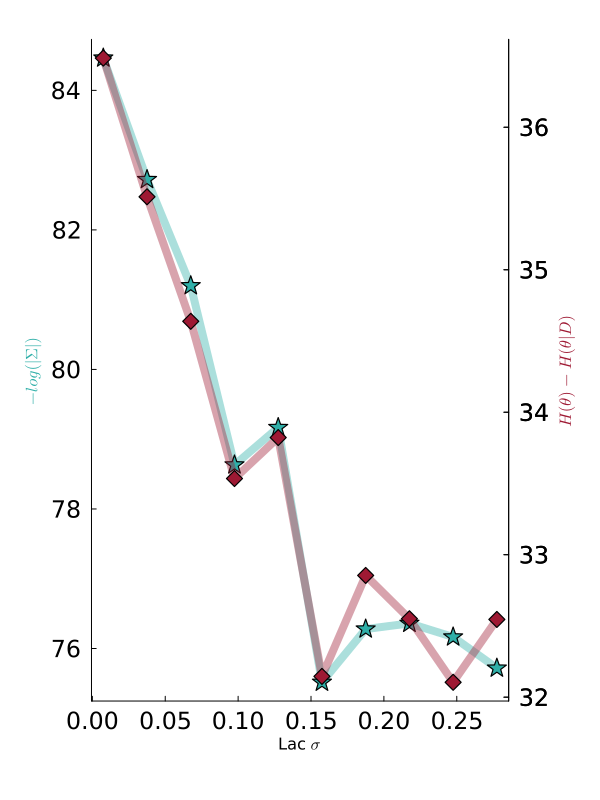

In [21]:
pps1 = plot(sigm2, cvsN, label = "", grid=false, xlabel = "Lac "*L"\sigma", ylabel = L"-log(|\Sigma|)", width=8, colour = "#2fafa8", alpha = 0.4, yguidefontcolor="#2fafa8", 
            size = (600,800),xtickfont=font(16), ytickfont=font(16), margins=8Plots.mm)
scatter!(sigm2, cvsN, label = "", grid=false, xlabel = "Lac "*L"\sigma", ylabel = L"-log(|\Sigma|)", markersize = 10, markershape=:star5, colour = "#2fafa8")

plot!(twinx(), sigm2, hetN, label = "", grid=false, xlabel = "", ylabel = L"H(\theta) - H(\theta | D)", width=8, colour = "#9e1933", alpha = 0.4, yguidefontcolor="#9e1933",ytickfont=font(16))
scatter!(twinx(), sigm2, hetN, label = "", grid=false, xlabel = "", ylabel = "", markersize = 8, markershape=:diamond, colour = "#9e1933",ytickfont=font(16))

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure5Stuff\\NoiseContribution.svg")

display(pps1)

# Lactate Predicitons Models

In [17]:
mainD = "C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ProcessedData\\";
# datsD = ["3Mil_0-0mMPyr_Dat","3Mil_0-6mMPyr_Dat","3Mil_0-8mMPyr_Dat","3Mil_1-6mMPyr_Dat","3Mil_3-2mMPyr_Dat", "3Mil_4-9mMPyr_Dat","3Mil_6-0mMPyr_Dat","3Mil_6-4mMPyr_Dat","3Mil_8-3mMPyr_Dat","3Mil_12-8mMPyr_Dat","3Mil_13-1mMPyr_Dat","3Mil_18-0mMPyr_Dat","3Mil_25-6mMPyr_Dat","3Mil_29-6mMPyr_Dat","3Mil_40-0mMPyr_Dat"]

datsD = ["3Mil_0-0mMPyr_Dat","3Mil_0-6mMPyr_Dat","3Mil_0-8mMPyr_Dat","3Mil_1-6mMPyr_Dat","3Mil_3-2mMPyr_Dat", "3Mil_6-0mMPyr_Dat","3Mil_6-4mMPyr_Dat","3Mil_8-3mMPyr_Dat","3Mil_12-8mMPyr_Dat","3Mil_13-1mMPyr_Dat","3Mil_18-0mMPyr_Dat","3Mil_25-6mMPyr_Dat","3Mil_29-6mMPyr_Dat","3Mil_40-0mMPyr_Dat"]

allD = [Matrix(CSV.read(mainD*datsD[i]*".csv", DataFrame)) for i in 1:length(datsD)];

#### Coeficient of Variation of our Data

In [18]:
# cns = [0,0.6,0.8,1.6,3.2,4.9,6,6.4,8.3,12.8,13.1,18,25.6,29,40]
cns = [0,0.6,0.8,1.6,3.2,6,6.4,8.3,12.8,13.1,18,25.6,29,40]


CVs = []
CVms = zeros(length(datsD),3)
for i in 1:length(datsD)
    CV = allD[i][2:40,5]./allD[i][2:40,4]
    CVms[i,1] = mean(CV[2:end])
    CVms[i,2] = std(CV[2:end])
    CVms[i,3] = sum(CV[2:end])
    push!(CVs, CV)
end

CVsRe = zeros(39,length(CVs[2:end]))
for i in 1:length(CVs[2:end])
    CVsRe[:,i] = CVs[i+1]
end
# scatter(cns[2:end], CVms[:,3][2:end])
# scatter(cns[2:end], CVms[:,1][2:end], yerror = CVms[:,2][2:end], label = "")


In [29]:
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ProcessedData\\CefVarDat.jld", "CVs", CVs)

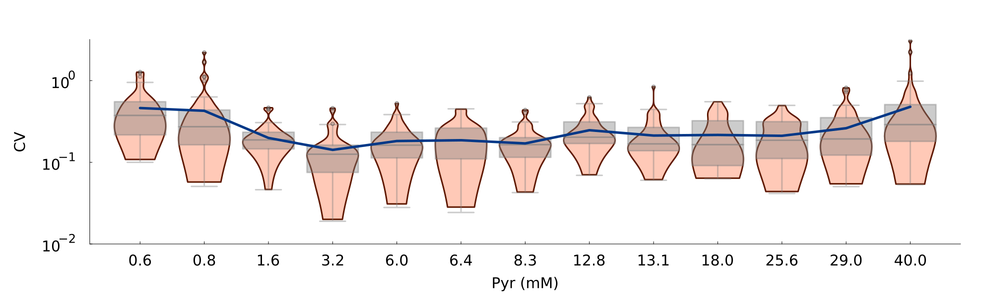

In [19]:
ppr1 = violin(reshape(collect(1:length(CVs[2:end])), 1, length(CVs[2:end])), CVsRe, xticks = (1:length(cns[2:end]), cns[2:end]), label = "", grid = false,  linecolour="#5f1800ff", colour = "#ffc9b7ff", linewidth=3, yscale=:log10,
        xlabel = "Pyr (mM)", ylabel = "CV", size = (2000,600),xtickfont=font(20), ytickfont=font(20), margins=18Plots.mm, guidefontsize = 20, ylim = (1e-2,3.2))
boxplot!(reshape(collect(1:length(CVs[2:end])), 1, length(CVs[2:end])), CVsRe, label = "", linecolour="grey", colour = "grey", linewidth=3, markersize = 4, alpha = 0.4)
plot!([mean(CVs[i][2:end]) for i in 2:length(CVs)], linewidth = 5, label = "", colour="#003887ff")

# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure5Stuff\\CoeficientVariationData.svg")

display(ppr1)

#### Prediction Validation Plot

In [20]:
function simDwnExp(expS, datsD, PyrCons, nSamps, poster, allD, plt = false)
    tsC2 = vcat(collect(0:5:395));
    ts = 0:tsC2[end];
    samps = convert.(Int, tsC2);


    exin = findall(expS .== datsD)
    postDwn = poster[StatsBase.sample(1:size(poster)[1], nSamps, replace = false),:]

    scF = allD[exin][1][1,2]/(PyrCons[1]*1000*0.12)

    simsPrior = Array{Any}(undef, nSamps);
    for i in 1:nSamps
        ivss = [round(PyrCons[1], digits = 1)*1000, 0, 0, postDwn[i,14], postDwn[i,15], postDwn[i,16], 0, 0, 0, 0, 0, round(PyrCons[1], digits = 1)*1000, 0, round(PyrCons[1], digits = 1)*1000*(scF*0.12)];;
        samps = convert.(Int, tsC2);

        SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(postDwn[i,1:12], scF, 0), ivss, samps);
        simsPrior[i] = SimulsAll;
    end


    # Dims = Up/Down, Observable, Experiment
    PriorQuant = Array{Any}(undef,2,1,1);
    lacPirorSims = zeros(size(simsPrior[1])[1], nSamps)
    [lacPirorSims[:,i] = simsPrior[i][:,13,1] for i in 1:nSamps ];
    for k in 1:1
        for m in 1:1
            PriorQuant[1,k,m] = [percentile(lacPirorSims[j,:], 99.5) for j in 1:size(lacPirorSims)[1]]; # Up
            PriorQuant[2,k,m] = [percentile(lacPirorSims[j,:], 0.5 ) for j in 1:size(lacPirorSims)[1]]; # Down
        end
    end

    if plt == true
        pr = scatter(allD[exin][1][:,1]./60, allD[exin][1][:,4], yerror = allD[exin][1][:,5], label = "")
        plot!(tsC2./60, PriorQuant[1], label = "", color = "red", linewidth = 3,
            margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
            xlabel = "time (min)", ylabel = "Lactate (AU)")
        plot!(tsC2./60, PriorQuant[2], label = "", color = "red", linewidth = 3)
        plot!(tsC2./60, PriorQuant[1], fillrange=PriorQuant[2], label="", color="red", fillalpha=0.2)

        display(pr)
    end

    return(simsPrior, PriorQuant)

end

simDwnExp (generic function with 2 methods)

In [31]:
Random.seed!(78956321)

expSA = "3Mil_1-6mMPyr_Dat"
PyrConsA = [1.6]
# expSA = "3Mil_4-9mMPyr_Dat"
# PyrConsA = [4.9]
nSamps = 8000#100

simsPrior1A, PriorQuant1A = simDwnExp(expSA, datsD, PyrConsA, nSamps, poster1, allD, false);

simsPriorR2A, PriorQuantR2A = simDwnExp(expSA, datsD, PyrConsA, nSamps, posterR2, allD, false);
simsPriorR3A, PriorQuantR3A = simDwnExp(expSA, datsD, PyrConsA, nSamps, posterR3, allD, false);

simsPriorR3bA, PriorQuantR3bA = simDwnExp(expSA, datsD, PyrConsA, nSamps, posterR3b, allD, false);

simsPriorI2A, PriorQuantI2A = simDwnExp(expSA, datsD, PyrConsA, nSamps, posterI2, allD, false);
simsPriorI3A, PriorQuantI3A = simDwnExp(expSA, datsD, PyrConsA, nSamps, posterI3, allD, false);

simsPriorO2A, PriorQuantO2A = simDwnExp(expSA, datsD, PyrConsA, nSamps, posterO2, allD, false);
simsPriorO3A, PriorQuantO3A = simDwnExp(expSA, datsD, PyrConsA, nSamps, posterO3, allD, false);

simsPriorO3bA, PriorQuantO3bA = simDwnExp(expSA, datsD, PyrConsA, nSamps, posterO3b, allD, false);


Random.seed!(78956321)

expSB = "3Mil_29-6mMPyr_Dat"
PyrConsB = [29.6]
nSamps = 8000#100

simsPrior1B, PriorQuant1B = simDwnExp(expSB, datsD, PyrConsB, nSamps, poster1, allD, false);

simsPriorR2B, PriorQuantR2B = simDwnExp(expSB, datsD, PyrConsB, nSamps, posterR2, allD, false);
simsPriorR3B, PriorQuantR3B = simDwnExp(expSB, datsD, PyrConsB, nSamps, posterR3, allD, false);

simsPriorR3bB, PriorQuantR3bB = simDwnExp(expSB, datsD, PyrConsB, nSamps, posterR3b, allD, false);

simsPriorI2B, PriorQuantI2B = simDwnExp(expSB, datsD, PyrConsB, nSamps, posterI2, allD, false);
simsPriorI3B, PriorQuantI3B = simDwnExp(expSB, datsD, PyrConsB, nSamps, posterI3, allD, false);

simsPriorO2B, PriorQuantO2B = simDwnExp(expSB, datsD, PyrConsB, nSamps, posterO2, allD, false);
simsPriorO3B, PriorQuantO3B = simDwnExp(expSB, datsD, PyrConsB, nSamps, posterO3, allD, false);

simsPriorO3bB, PriorQuantO3bB = simDwnExp(expSB, datsD, PyrConsB, nSamps, posterO3b, allD, false);

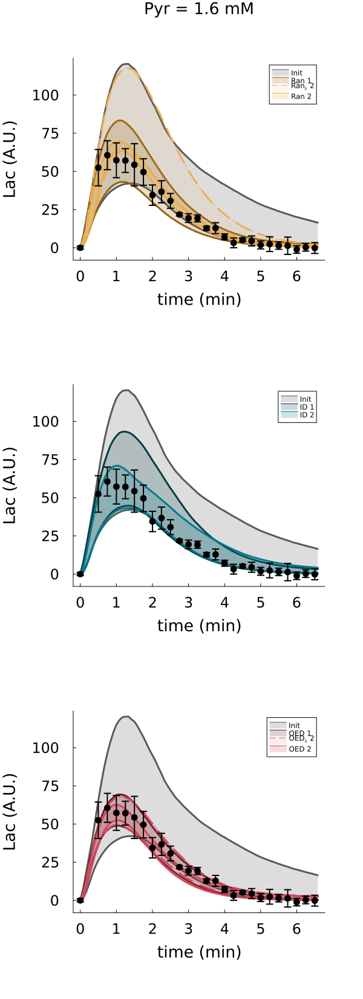

In [36]:
tsC2 = vcat(collect(0:5:395));
ts = 0:tsC2[end];
samps = convert.(Int, tsC2);
indD1 = findfirst(datsD .== expSA)





PPTS1 = plot(tsC2./60, PriorQuant1A[1], label = "", color = "#595959ff", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Lac (A.U.)", grid = false, title = "Pyr = "*string(PyrConsA[1])*" mM")
plot!(tsC2./60, PriorQuant1A[2], label = "", color = "#595959ff", linewidth = 3)
plot!(tsC2./60, PriorQuant1A[1], fillrange=PriorQuant1A[2], label="Init", color="#595959ff", fillalpha=0.2)


plot!(tsC2./60, PriorQuantR2A[1], label = "", color = "#97630fff", linewidth = 3)
plot!(tsC2./60, PriorQuantR2A[2], label = "", color = "#97630fff", linewidth = 3)
plot!(tsC2./60, PriorQuantR2A[1], fillrange=PriorQuantR2A[2], label="Ran 1", color="#97630fff", fillalpha=0.2)


plot!(tsC2./60, PriorQuantR3bA[1], label = "", color = "#edae49ff", linewidth = 3, linestyle=:dash)
plot!(tsC2./60, PriorQuantR3bA[2], label = "", color = "#edae49ff", linewidth = 3, linestyle=:dash)
plot!(tsC2./60, PriorQuantR3bA[1], fillrange=PriorQuantR3bA[2], label="Ran"*L"_b"*" 2", color="#edae49ff", fillalpha=0.1, linestyle=:dash)

plot!(tsC2./60, PriorQuantR3A[1], label = "", color = "#edae49ff", linewidth = 3)
plot!(tsC2./60, PriorQuantR3A[2], label = "", color = "#edae49ff", linewidth = 3)
plot!(tsC2./60, PriorQuantR3A[1], fillrange=PriorQuantR3A[2], label="Ran 2", color="#edae49ff", fillalpha=0.2)

scatter!(allD[indD1][1:3:end,1]./60, allD[indD1][1:3:end,4], yerror = allD[indD1][1:3:end,5], label = "", colour = "black", linewidth=2, markersize=6)



PPTS2 = plot(tsC2./60, PriorQuant1A[1], label = "", color = "#595959ff", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Lac (A.U.)", grid = false)
plot!(tsC2./60, PriorQuant1A[2], label = "", color = "#595959ff", linewidth = 3)
plot!(tsC2./60, PriorQuant1A[1], fillrange=PriorQuant1A[2], label="Init", color="#595959ff", fillalpha=0.2)


plot!(tsC2./60, PriorQuantI2A[1], label = "", color = "#003c43ff", linewidth = 3)
plot!(tsC2./60, PriorQuantI2A[2], label = "", color = "#003c43ff", linewidth = 3)
plot!(tsC2./60, PriorQuantI2A[1], fillrange=PriorQuantI2A[2], label="ID 1", color="#003c43ff", fillalpha=0.2)


plot!(tsC2./60, PriorQuantI3A[1], label = "", color = "#00798cff", linewidth = 3)
plot!(tsC2./60, PriorQuantI3A[2], label = "", color = "#00798cff", linewidth = 3)
plot!(tsC2./60, PriorQuantI3A[1], fillrange=PriorQuantI3A[2], label="ID 2", color="#00798cff", fillalpha=0.2)

scatter!(allD[indD1][1:3:end,1]./60, allD[indD1][1:3:end,4], yerror = allD[indD1][1:3:end,5], label = "", colour = "black", linewidth=2, markersize=6)



PPTS3 = plot(tsC2./60, PriorQuant1A[1], label = "", color = "#595959ff", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Lac (A.U.)", grid = false)
plot!(tsC2./60, PriorQuant1A[2], label = "", color = "#595959ff", linewidth = 3)
plot!(tsC2./60, PriorQuant1A[1], fillrange=PriorQuant1A[2], label="Init", color="#595959ff", fillalpha=0.2)


plot!(tsC2./60, PriorQuantO2A[1], label = "", color = "#6c1b26ff", linewidth = 3)
plot!(tsC2./60, PriorQuantO2A[2], label = "", color = "#6c1b26ff", linewidth = 3)
plot!(tsC2./60, PriorQuantO2A[1], fillrange=PriorQuantO2A[2], label="OED 1", color="#6c1b26ff", fillalpha=0.2)

plot!(tsC2./60, PriorQuantO3bA[1], label = "", color = "#d1495bff", linewidth = 3, linestyle=:dash)
plot!(tsC2./60, PriorQuantO3bA[2], label = "", color = "#d1495bff", linewidth = 3, linestyle=:dash)
plot!(tsC2./60, PriorQuantO3bA[1], fillrange=PriorQuantO3bA[2], label="OED"*L"_b"*" 2", color="#d1495bff", fillalpha=0.1, linestyle=:dash)

plot!(tsC2./60, PriorQuantO3A[1], label = "", color = "#d1495bff", linewidth = 3)
plot!(tsC2./60, PriorQuantO3A[2], label = "", color = "#d1495bff", linewidth = 3)
plot!(tsC2./60, PriorQuantO3A[1], fillrange=PriorQuantO3A[2], label="OED 2", color="#d1495bff", fillalpha=0.2)

scatter!(allD[indD1][1:3:end,1]./60, allD[indD1][1:3:end,4], yerror = allD[indD1][1:3:end,5], label = "", colour = "black", linewidth=2, markersize=6)


fpp = plot(PPTS1, PPTS2, PPTS3, layout = (3,1), size = (600,1650), margin=14Plots.mm)

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure5Stuff\\ValidationLac1.svg")

display(fpp)

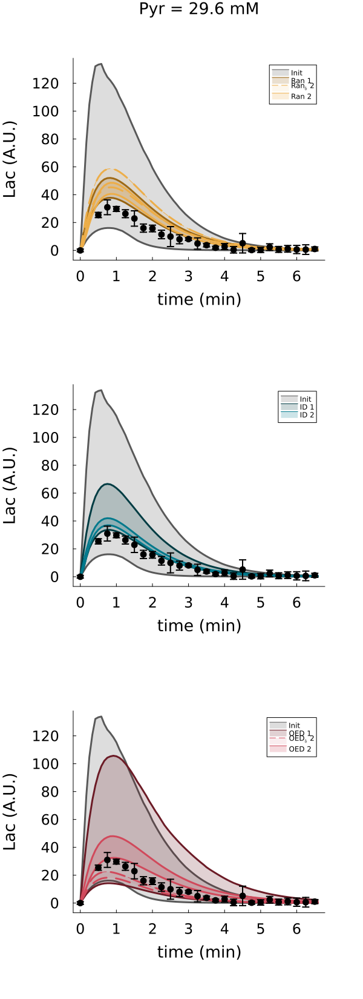

In [37]:
tsC2 = vcat(collect(0:5:395));
ts = 0:tsC2[end];
samps = convert.(Int, tsC2);
indD1 = findfirst(datsD .== expSB)





PPTS1 = plot(tsC2./60, PriorQuant1B[1], label = "", color = "#595959ff", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Lac (A.U.)", grid = false, title = "Pyr = "*string(PyrConsB[1])*" mM")
plot!(tsC2./60, PriorQuant1B[2], label = "", color = "#595959ff", linewidth = 3)
plot!(tsC2./60, PriorQuant1B[1], fillrange=PriorQuant1B[2], label="Init", color="#595959ff", fillalpha=0.2)


plot!(tsC2./60, PriorQuantR2B[1], label = "", color = "#97630fff", linewidth = 3)
plot!(tsC2./60, PriorQuantR2B[2], label = "", color = "#97630fff", linewidth = 3)
plot!(tsC2./60, PriorQuantR2B[1], fillrange=PriorQuantR2B[2], label="Ran 1", color="#97630fff", fillalpha=0.2)

plot!(tsC2./60, PriorQuantR3bB[1], label = "", color = "#edae49ff", linewidth = 3, linestyle=:dash)
plot!(tsC2./60, PriorQuantR3bB[2], label = "", color = "#edae49ff", linewidth = 3, linestyle=:dash)
plot!(tsC2./60, PriorQuantR3bB[1], fillrange=PriorQuantR3bB[2], label="Ran"*L"_b"*" 2", color="#edae49ff", fillalpha=0.1, linestyle=:dash)

plot!(tsC2./60, PriorQuantR3B[1], label = "", color = "#edae49ff", linewidth = 3)
plot!(tsC2./60, PriorQuantR3B[2], label = "", color = "#edae49ff", linewidth = 3)
plot!(tsC2./60, PriorQuantR3B[1], fillrange=PriorQuantR3B[2], label="Ran 2", color="#edae49ff", fillalpha=0.2)

scatter!(allD[indD1][1:3:end,1]./60, allD[indD1][1:3:end,4], yerror = allD[indD1][1:3:end,5], label = "", colour = "black", linewidth=2, markersize=6)



PPTS2 = plot(tsC2./60, PriorQuant1B[1], label = "", color = "#595959ff", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Lac (A.U.)", grid = false)
plot!(tsC2./60, PriorQuant1B[2], label = "", color = "#595959ff", linewidth = 3)
plot!(tsC2./60, PriorQuant1B[1], fillrange=PriorQuant1B[2], label="Init", color="#595959ff", fillalpha=0.2)


plot!(tsC2./60, PriorQuantI2B[1], label = "", color = "#003c43ff", linewidth = 3)
plot!(tsC2./60, PriorQuantI2B[2], label = "", color = "#003c43ff", linewidth = 3)
plot!(tsC2./60, PriorQuantI2B[1], fillrange=PriorQuantI2B[2], label="ID 1", color="#003c43ff", fillalpha=0.2)


plot!(tsC2./60, PriorQuantI3B[1], label = "", color = "#00798cff", linewidth = 3)
plot!(tsC2./60, PriorQuantI3B[2], label = "", color = "#00798cff", linewidth = 3)
plot!(tsC2./60, PriorQuantI3B[1], fillrange=PriorQuantI3B[2], label="ID 2", color="#00798cff", fillalpha=0.2)

scatter!(allD[indD1][1:3:end,1]./60, allD[indD1][1:3:end,4], yerror = allD[indD1][1:3:end,5], label = "", colour = "black", linewidth=2, markersize=6)



PPTS3 = plot(tsC2./60, PriorQuant1B[1], label = "", color = "#595959ff", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Lac (A.U.)", grid = false)
plot!(tsC2./60, PriorQuant1B[2], label = "", color = "#595959ff", linewidth = 3)
plot!(tsC2./60, PriorQuant1B[1], fillrange=PriorQuant1B[2], label="Init", color="#595959ff", fillalpha=0.2)


plot!(tsC2./60, PriorQuantO2B[1], label = "", color = "#6c1b26ff", linewidth = 3)
plot!(tsC2./60, PriorQuantO2B[2], label = "", color = "#6c1b26ff", linewidth = 3)
plot!(tsC2./60, PriorQuantO2B[1], fillrange=PriorQuantO2B[2], label="OED 1", color="#6c1b26ff", fillalpha=0.2)


plot!(tsC2./60, PriorQuantO3bB[1], label = "", color = "#d1495bff", linewidth = 3, linestyle=:dash)
plot!(tsC2./60, PriorQuantO3bB[2], label = "", color = "#d1495bff", linewidth = 3, linestyle=:dash)
plot!(tsC2./60, PriorQuantO3bB[1], fillrange=PriorQuantO3bB[2], label="OED"*L"_b"*" 2", color="#d1495bff", fillalpha=0.1, linestyle=:dash)

plot!(tsC2./60, PriorQuantO3B[1], label = "", color = "#d1495bff", linewidth = 3)
plot!(tsC2./60, PriorQuantO3B[2], label = "", color = "#d1495bff", linewidth = 3)
plot!(tsC2./60, PriorQuantO3B[1], fillrange=PriorQuantO3B[2], label="OED 2", color="#d1495bff", fillalpha=0.2)

scatter!(allD[indD1][1:3:end,1]./60, allD[indD1][1:3:end,4], yerror = allD[indD1][1:3:end,5], label = "", colour = "black", linewidth=2, markersize=6)


fpp = plot(PPTS1, PPTS2, PPTS3, layout = (3,1), size = (600,1400), margin=14Plots.mm)
fpp = plot(PPTS1, PPTS2, PPTS3, layout = (3,1), size = (600,1650), margin=14Plots.mm)


savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure5Stuff\\ValidationLac2.svg")

display(fpp)

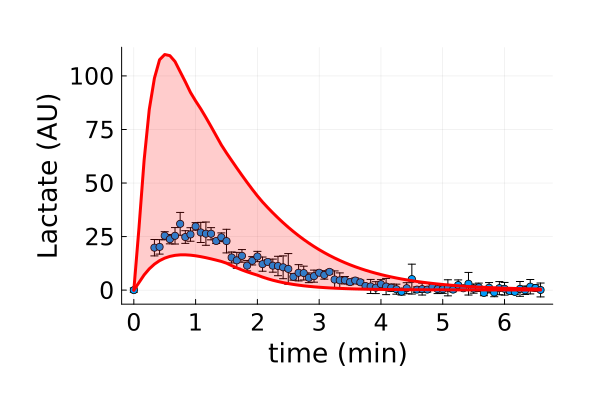

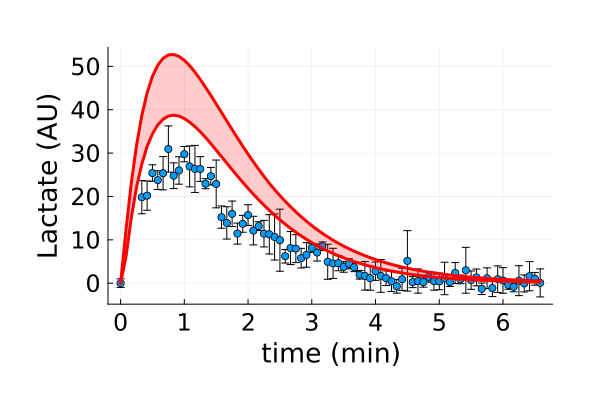

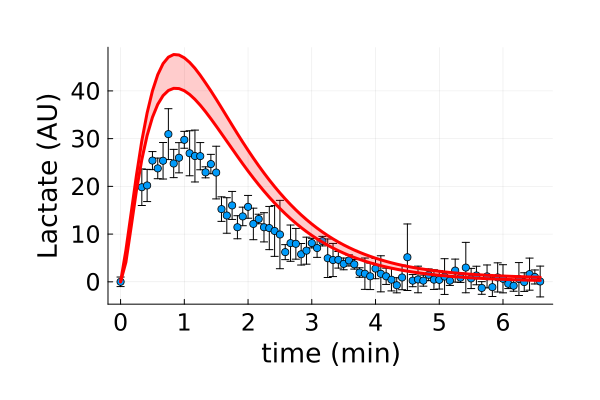

In [311]:
Random.seed!(78956321)

expS = "3Mil_29-6mMPyr_Dat"
PyrCons = [29.6]
nSamps = 100

simDwnExp(expS, datsD, PyrCons, nSamps, poster1, allD, true);
simDwnExp(expS, datsD, PyrCons, nSamps, posterR2, allD, true);
simDwnExp(expS, datsD, PyrCons, nSamps, posterR3, allD, true);

# Data Against Simulations

In [21]:
mainP = "C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\RawData_DiffPyr\\"

expsP = [["0.0Pyr_2025_04_18_DGC_HepG2_3Mil_0mMPyruvate_NewTryControl1","0.0Pyr_2025_04_18_DGC_HepG2_3Mil_0mMPyruvate_NewTryControl2","0.0Pyr_2025_04_18_DGC_HepG2_3Mil_0mMPyruvate_NewTryControl3"],
         ["0.6Pyr_2025_03_26_DGC_HepG2_3Mil_0.6mMPyruvate_NewTryControl1","0.6Pyr_2025_03_24_DGC_HepG2_3Mil_0.6mMPyruvate_NewTryControl4","0.6Pyr_2025_03_24_DGC_HepG2_3Mil_0.6mMPyruvate_NewTryControl3"],
         ["0.8Pyr_2025_03_13_DGC_HepG2_3Mil_0.8mMPyruvate_NewTryControl1","0.8Pyr_2025_03_23_DGC_HepG2_3Mil_0.8mMPyruvate_NewTryControl1","0.8Pyr_2025_03_23_DGC_HepG2_3Mil_0.8mMPyruvate_NewTryControl2"],
         ["1.6Pyr_2025_03_26_DGC_HepG2_3Mil_1.6mMPyruvate_NewTryControl2","1.6Pyr_2025_03_24_DGC_HepG2_3Mil_1.6mMPyruvate_NewTryControl1","1.6Pyr_2025_03_26_DGC_HepG2_3Mil_1.6mMPyruvate_NewTryControl1"],
         ["3.2Pyr_2025_02_05_DGC_HepG2_3Mil_3.2mMPyruvate_NewTryControl","3.2Pyr_2025_02_05_DGC_HepG2_3Mil_3.2mMPyruvate_NewTryControl2","3.2Pyr_2025_02_14_DGC_HepG2_3Mil_3.2mMPyruvate_NewTryControl1"],
        #  ["4.9Pyr_2025_07_18_DGC_HepG2_3Mil_4.9mMPyruvate_NewTryControl2","4.9Pyr_2025_07_18_DGC_HepG2_3Mil_4.9mMPyruvate_NewTryControl3","4.9Pyr_2025_07_22_DGC_HepG2_3Mil_4.9mMPyruvate_NewTryControl2"],
         ["6.0Pyr_2025_04_18_DGC_HepG2_3Mil_6mMPyruvate_NewTryControl1","6.0Pyr_2025_04_18_DGC_HepG2_3Mil_6mMPyruvate_NewTryControl2","6.0Pyr_2025_05_09_DGC_HepG2_3Mil_6mMPyruvate_NewTryControl1_NEW"],
         ["6.4Pyr_2025_03_12_DGC_HepG2_3Mil_6.4mMPyruvate_NewTryControl1","6.4Pyr_2025_03_12_DGC_HepG2_3Mil_6.4mMPyruvate_NewTryControl2","6.4Pyr_2025_03_12_DGC_HepG2_3Mil_6.4mMPyruvate_NewTryControl3"],
         ["8.3Pyr_2025_06_12_DGC_HepG2_3Mil_8.3mMPyruvate_NewTryControl1","8.3Pyr_2025_06_12_DGC_HepG2_3Mil_8.3mMPyruvate_NewTryControl3","8.3Pyr_2025_06_12_DGC_HepG2_3Mil_8.3mMPyruvate_NewTryControl4"],
         ["12.8Pyr_2025_03_12_DGC_HepG2_3Mil_12.8mMPyruvate_NewTryControl1","12.8Pyr_2025_03_13_DGC_HepG2_3Mil_12.8mMPyruvate_NewTryControl2","12.8Pyr_2025_03_13_DGC_HepG2_3Mil_12.8mMPyruvate_NewTryControl3"],
         ["13.1Pyr_2025_08_04_DGC_HepG2_3Mil_13.1mMPyruvate_NewTryControl1","13.1Pyr_2025_08_04_DGC_HepG2_3Mil_13.1mMPyruvate_NewTryControl2","13.1Pyr_2025_08_04_DGC_HepG2_3Mil_13.1mMPyruvate_NewTryControl3"],
         ["18.0Pyr_2025_07_09_DGC_HepG2_3Mil_18mMPyruvate_NewTryControl2","18.0Pyr_2025_07_09_DGC_HepG2_3Mil_18mMPyruvate_NewTryControl3","18.0Pyr_2025_07_09_DGC_HepG2_3Mil_18mMPyruvate_NewTryControl4"],
         ["25.6Pyr_2025_03_20_DGC_HepG2_3Mil_25.6mMPyruvate_NewTryControl1","25.6Pyr_2025_03_20_DGC_HepG2_3Mil_25.6mMPyruvate_NewTryControl2","25.6Pyr_2025_03_20_DGC_HepG2_3Mil_25.6mMPyruvate_NewTryControl3"],
         ["29.6Pyr_2025_06_13_DGC_HepG2_3Mil_29.6mMPyruvate_NewTryControl1","29.6Pyr_2025_06_13_DGC_HepG2_3Mil_29.6mMPyruvate_NewTryControl2","29.6Pyr_2025_06_13_DGC_HepG2_3Mil_29.6mMPyruvate_NewTryControl3"],
         ["40.0Pyr_2025_03_21_DGC_HepG2_3Mil_40mMPyruvate_NewTryControl1","40.0Pyr_2025_03_21_DGC_HepG2_3Mil_40mMPyruvate_NewTryControl2","40.0Pyr_2025_03_21_DGC_HepG2_3Mil_40mMPyruvate_NewTryControl3"]]

# cns = [0,0.6,0.8,1.6,3.2,4.9,6,6.4,8.3,12.8,13.1,18,25.6,29,40]
cns = [0,0.6,0.8,1.6,3.2,6,6.4,8.3,12.8,13.1,18,25.6,29.6,40]

Matrix(CSV.read(mainP*expsP[5][1]*".csv", DataFrame))

80×5 Matrix{Any}:
   0  8908.21      0.432911   missing  "3.2 Good"
   5  8002.09      0.0990377  missing  missing
  10  7106.47     -2.5639     missing  missing
  15  6998.51     24.4311     missing  missing
  20  6211.92     35.1748     missing  missing
  25  5565.78     47.1715     missing  missing
  30  5022.72     57.3        missing  missing
  35  4512.38     56.0712     missing  missing
  40  4058.06     63.2657     missing  missing
  45  3717.37     63.7562     missing  missing
  50  3320.02     68.2423     missing  missing
  55  2991.2      64.7945     missing  missing
  60  2677.71     71.9379     missing  missing
   ⋮                                   
 340    11.1576    7.21682    missing  missing
 345     9.8823    1.77935    missing  missing
 350     4.86158   5.88342    missing  missing
 355     3.75297   1.02128    missing  missing
 360     4.25025  -1.79685    missing  missing
 365    -3.7075   -0.412118   missing  missing
 370     9.67086  -3.45491    missing  missing

In [22]:
datmeA = Array{Any}(undef, length(expsP), 3)
for i in 1:length(expsP)
    for j in 1:3
        datmeA[i,j] = Matrix(CSV.read(mainP*expsP[i][j]*".csv", DataFrame))
    end
end

#### Extrapolate P0

In [23]:
using Polynomials 
using Trapz
using EasyFit
using LsqFit

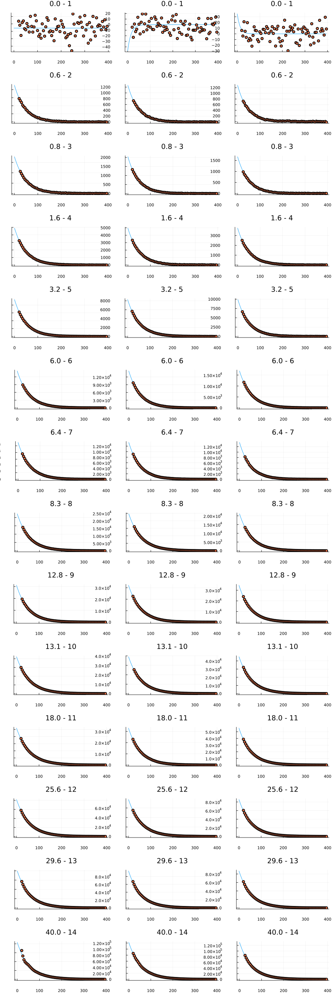

In [24]:
# Fit T1, extract P0
T1s = zeros(length(expsP), 3);
P0s = zeros(length(expsP), 3);

m(t,p) =  p[1].*exp.(-t.*p[2]);
p0 = [10000, 0.01];

pltT1 = Array{Any}(undef, length(expsP))

for i in 1:length(expsP)
    tmpPl = Array{Any}(undef, 3)
    for j in 1:3

        if (i == 2 && j == 2) || (i == 2 && j == 3) || (i == 3 && j == 1) || (i == 3 && j == 3) || (i == 6 && j == 1) || (i == 7 && j == 3) || (i == 8 && j == 1) || (i == 8 && j == 2) || 
           (i == 8 && j == 3) || (i == 9 && j == 1) || (i == 10 && j == 2) || (i == 14 && j == 3)
            t = datmeA[i,j][6:end,1];
            d = datmeA[i,j][6:end,2];
        else
            t = datmeA[i,j][5:end,1];
            d = datmeA[i,j][5:end,2];
        end

        fit = curve_fit(m, t, d, p0);

        pp=plot(datmeA[i,j][:,1], m(datmeA[i,j][:,1], coef(fit)), title=string(cns[i])*" - "*string(i), label = "")
        scatter!(t, d, label = "")

        tmpPl[j] = pp

        T1s[i,j] = 1/coef(fit)[2];
        P0s[i,j] = m(datmeA[i,j][1,1], coef(fit));

        # display(pp)

    end
    pltT1[i] = plot(tmpPl..., layout=(1,3))
end

P0s[1,:] = [mean(datmeA[1,:][i][:,2]) for i in 1:3]

plot(pltT1..., layout=(length(expsP),1), size = (1000,3000))

#### Compute Experimental Curve

In [25]:
data = DataFrame(X=vcat(cns, cns, cns), Y=vcat(P0s[:,1], P0s[:,2], P0s[:,3]))
ols = lm(@formula(Y ~ X), data)

StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

Y ~ 1 + X

Coefficients:
────────────────────────────────────────────────────────────────────────
                Coef.  Std. Error      t  Pr(>|t|)  Lower 95%  Upper 95%
────────────────────────────────────────────────────────────────────────
(Intercept)  -1882.81    1234.45   -1.53    0.1351   -4377.73    612.102
X             3067.39      73.486  41.74    <1e-33    2918.87   3215.91
────────────────────────────────────────────────────────────────────────

In [43]:
r2(ols)

0.9775573273952788

# !!!!! FIGURE FOR SUPPLEMENTARY !!!!!!

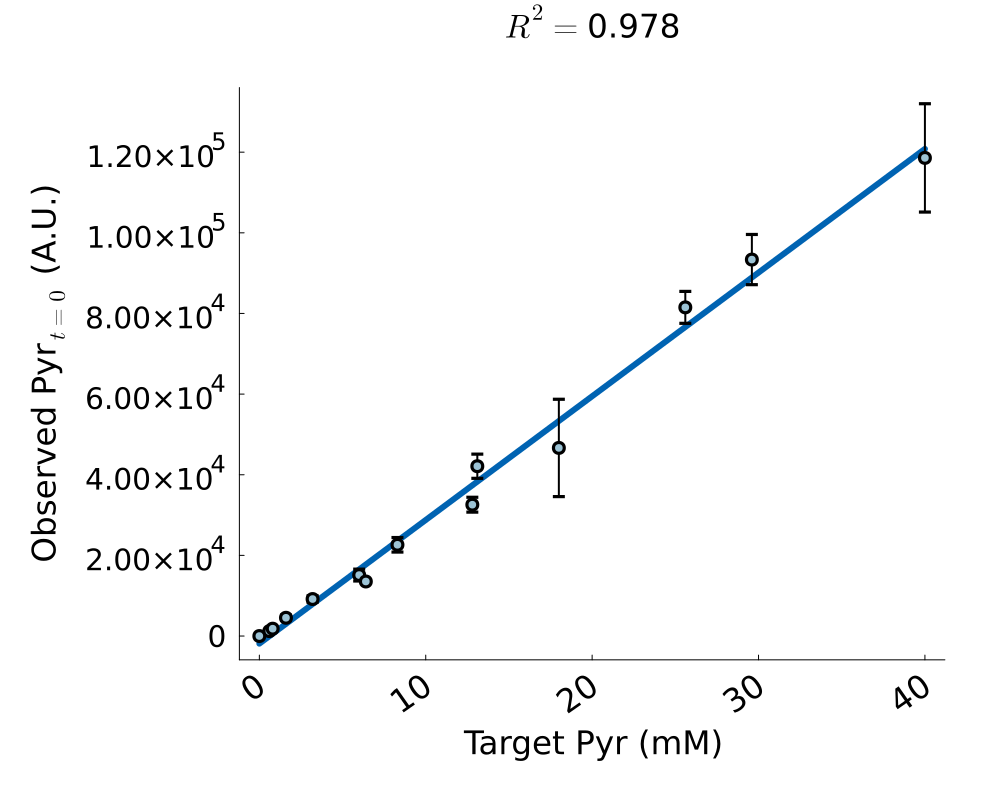

In [29]:
PPS = plot(0:40, predict(ols, DataFrame(X = 0:40)), title = L"R^2 = "*string(round(r2(ols), digits=3)), label = "", linewidth = 6, xlabel = "Target Pyr (mM)", ylabel = "Observed Pyr"*L"_{t=0}"*" (A.U.)", markersize = 10, margin=12Plots.mm,xtickfont=font(22), 
        ytickfont=font(20), guidefont=font(22), titlefont=font(22),
        xrotation = 35, size = (1000,800), colour="#0063B2")
scatter!(cns, mean(P0s[:,:], dims = 2), yerror = std(P0s[:,:], dims = 2), label = "", grid = false, markersize=6, markerstrokewidth=2, colour = "#9CC3D5")

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\SuppFig15Stuff\\PyrObsTarg.svg")

display(PPS)

In [26]:
# obs = cns*0.12*ScF

ScFs = P0s./(0.12 .*cns*1000);
ScFs[1,:] .= mean(ScFs[2:end,:]);
ScFs

14×3 Matrix{Float64}:
 22.4601  22.4601  22.4601
 15.7407  17.5127  17.836
 18.4479  21.2143  17.3701
 25.4596  25.7591  19.5459
 24.4382  21.5414  25.7196
 19.7901  19.8536  23.3556
 17.8877  17.3417  17.6136
 22.2607  24.7164  21.1853
 20.1907  20.8962  22.5346
 26.8768  24.8415  28.657
 23.9642  15.2182  25.6156
 26.566   25.2282  27.805
 27.9634  26.422   24.4659
 21.6303  25.3782  27.1014

In [27]:
corDat = Array{Any}(undef, length(cns), 3)
for i in 1:length(cns)
    for j in 1:3
        corDat[i,j] = datmeA[i,j][:,2:3]./mean(ScFs[i,:])
    end
end

In [28]:
aucs = zeros(length(cns), 3)

for i in 1:length(cns)
    for j in 1:3
        if (i == 2 && j == 2) || (i == 2 && j == 3) || (i == 3 && j == 1) || (i == 3 && j == 3) || (i == 6 && j == 1) || (i == 7 && j == 3) || (i == 8 && j == 1) || (i == 8 && j == 2) || 
           (i == 8 && j == 3) || (i == 9 && j == 1) || (i == 10 && j == 2) || (i == 14 && j == 3)
            z = 6
        else
            z = 5
        end
        
        x = vcat(datmeA[i,j][1,1], datmeA[i,j][z:end,1])
        y = vcat(0, corDat[i,j][z:end,2])

        aucs[i,j] = trapz(convert.(Float64, x), convert.(Float64, y))
    end
end

# aucs[1,:] .= 0;

In [29]:
aucs

14×3 Matrix{Float64}:
   3.75425   -1.85201    9.25956
 194.869    106.51     111.451
 148.081    159.386    120.791
 382.328    405.639    288.321
 377.893    348.564    418.178
 405.425    361.368    317.851
 467.303    494.597    374.033
 351.742    338.91     281.736
 241.135    348.094    286.722
 214.727    192.487    263.579
 275.877    222.952    297.115
 183.267    220.34     202.742
 126.692    121.85     137.247
  73.3874    84.5412    89.9177

#### Generate Simulations

In [30]:
function simAllCns(poster, nSamps = 10, res = 1, plott = false)
    tsC2 = vcat(collect(0:5:395));
    ts = 0:tsC2[end];
    samps = convert.(Int, tsC2);

    postDwn = poster[StatsBase.sample(1:size(poster)[1], nSamps, replace = false),:]

    scF = 1;

    PyrCons4 = collect(0:res:40);
    ObsPyrCons4 = PyrCons4.*(1000*0.12*scF);

    posterSimsO = Array{Any}(undef, length(PyrCons4))
    for i in 1:length(PyrCons4)
        tmp = zeros(length(samps),14,nSamps);
        for j in 1:nSamps
            ivss = [PyrCons4[i].*1000, 0, 0, postDwn[j,end-2], postDwn[j,end-1], postDwn[j,end], 0, 0, 0, 0, 0, PyrCons4[i].*1000, 0, PyrCons4[i].*(1000*0.12*scF)];
            SimOnTime1poster, SimOffTime1poster, SimAll1poster  = PyruvateHP_NMR_SolveAllCp(ts, vcat(postDwn[j,1:end-4], scF, zeros(1)), ivss, samps);
            tmp[:,:,j] = SimOnTime1poster[:,:,1]
        end
        posterSimsO[i] = tmp;
    end

    sumSimsO = zeros(nSamps, length(ObsPyrCons4));
    [sumSimsO[j,i] = trapz(samps, posterSimsO[i][:,13,j]) for i in 1:length(ObsPyrCons4) for j in 1:nSamps];

    lacSumQuantO = Array{Any}(undef,2,length(PyrCons4));
    for m in 1:length(PyrCons4)
        lacSumQuantO[1,m] = percentile(sumSimsO[:,m], 95); # Up
        lacSumQuantO[2,m] = percentile(sumSimsO[:,m], 5 ); # Down
    end

    if plott == true
        ppt = plot(PyrCons4, lacSumQuantO[1,:], label = "", color = "red3",
            xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false)
        plot!(PyrCons4, lacSumQuantO[2,:], label = "", color = "red3", linewidth=0.6)
        plot!(PyrCons4, lacSumQuantO[2,:], fillrange=convert.(Float64, lacSumQuantO[1,:]), color="red3", fillalpha=0.2, linewidth = 0, label = "")

        display(ppt)
    end

    return(posterSimsO, sumSimsO, lacSumQuantO)
end

simAllCns (generic function with 4 methods)

In [31]:
# Iteration 2
rep = false

samps = 1000#100
disc1 = 0.2#1
mainP = "C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\ResultsPostAnal\\"
filch = "SimulationsPosteriorDiffPyrConc_Rand2.jld"

PyrCons4 = collect(0:disc1:40);
ObsPyrCons4 = PyrCons4.*(1000*0.12*1);

if isfile(mainP*filch) && rep == false
    println(1)
    tt1 = JLD2.load(mainP*"SimulationsPosteriorDiffPyrConc_Rand2.jld");
    tt2 = JLD2.load(mainP*"SimulationsPosteriorDiffPyrConc_InDr2.jld");
    tt3 = JLD2.load(mainP*"SimulationsPosteriorDiffPyrConc_bOED2.jld");
    posterSimsR2, sumSimsR2, lacSumQuantR2 = tt1["posterSimsR2"], tt1["sumSimsR2"], tt1["lacSumQuantR2"];
    posterSimsI2, sumSimsI2, lacSumQuantI2 = tt2["posterSimsI2"], tt2["sumSimsI2"], tt2["lacSumQuantI2"];
    posterSimsO2, sumSimsO2, lacSumQuantO2 = tt3["posterSimsO2"], tt3["sumSimsO2"], tt3["lacSumQuantO2"];
elseif !isfile(mainP*filch) || rep == true
    println(2)
    Random.seed!(456561325)
    posterSimsR2, sumSimsR2, lacSumQuantR2 = simAllCns(posterR2, samps, disc1, false);
    posterSimsI2, sumSimsI2, lacSumQuantI2 = simAllCns(posterI2, samps, disc1, false);
    posterSimsO2, sumSimsO2, lacSumQuantO2 = simAllCns(posterO2, samps, disc1, false);

    JLD2.save(mainP*"SimulationsPosteriorDiffPyrConc_Rand2.jld", "posterSimsR2", posterSimsR2, "sumSimsR2", sumSimsR2, "lacSumQuantR2", lacSumQuantR2);
    JLD2.save(mainP*"SimulationsPosteriorDiffPyrConc_InDr2.jld", "posterSimsI2", posterSimsI2, "sumSimsI2", sumSimsI2, "lacSumQuantI2", lacSumQuantI2);
    JLD2.save(mainP*"SimulationsPosteriorDiffPyrConc_bOED2.jld", "posterSimsO2", posterSimsO2, "sumSimsO2", sumSimsO2, "lacSumQuantO2", lacSumQuantO2);
end

1


(Any[[0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; … ;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0], [200.0 0.0 … 0.0 24.0; 180.87060146222979 0.5487053907721667 … 0.03310369783024934 21.735041387363914; … ; 0.07859465992809485 0.0023931494886057347 … 0.005581177628993214 0.004154113868546667; 0.07107731725049657 0.002359965620565982 … 0.005335159605409181 0.0034258403531209434;;; 200.0 0.0 … 0.0 24.0; 184.86121725375776 0.7632388104004582 … 0.0362131982958313 21.73174102835396; … ; 0.43118476014969276 0.01493224409983824 … 0.012403385279969294 -0.006727992559616851; 0.39854669831524236 0.01

In [32]:
# Iteration 3
rep = false

samps = 1000#100
disc2 = 0.2#0.1
mainP = "C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\ResultsPostAnal\\"
filch = "SimulationsPosteriorDiffPyrConc_Rand3.jld"

PyrCons4 = collect(0:disc2:40);
ObsPyrCons4 = PyrCons4.*(1000*0.12*1);

if isfile(mainP*filch) && rep == false
    println(1)
    tt1 = JLD2.load(mainP*"SimulationsPosteriorDiffPyrConc_Rand3.jld");
    tt2 = JLD2.load(mainP*"SimulationsPosteriorDiffPyrConc_InDr3.jld");
    tt3 = JLD2.load(mainP*"SimulationsPosteriorDiffPyrConc_bOED3.jld");
    posterSimsR3, sumSimsR3, lacSumQuantR3 = tt1["posterSimsR3"], tt1["sumSimsR3"], tt1["lacSumQuantR3"];
    posterSimsI3, sumSimsI3, lacSumQuantI3 = tt2["posterSimsI3"], tt2["sumSimsI3"], tt2["lacSumQuantI3"];
    posterSimsO3, sumSimsO3, lacSumQuantO3 = tt3["posterSimsO3"], tt3["sumSimsO3"], tt3["lacSumQuantO3"];

    tt4 = JLD2.load(mainP*"SimulationsPosteriorDiffPyrConc_Rand3b.jld");
    posterSimsR3b, sumSimsR3b, lacSumQuantR3b = tt4["posterSimsR3b"], tt4["sumSimsR3b"], tt4["lacSumQuantR3b"];

    tt5 = JLD2.load(mainP*"SimulationsPosteriorDiffPyrConc_bOED3b.jld");
    posterSimsO3b, sumSimsO3b, lacSumQuantO3b = tt5["posterSimsO3b"], tt5["sumSimsO3b"], tt5["lacSumQuantO3b"];
elseif !isfile(mainP*filch) || rep == true
    println(2)
    Random.seed!(456561325)
    posterSimsR3, sumSimsR3, lacSumQuantR3 = simAllCns(posterR3, samps, disc2, false);
    posterSimsI3, sumSimsI3, lacSumQuantI3 = simAllCns(posterI3, samps, disc2, false);
    posterSimsO3, sumSimsO3, lacSumQuantO3 = simAllCns(posterO3, samps, disc2, false);

    posterSimsO3b, sumSimsO3b, lacSumQuantO3b = simAllCns(posterO3b, samps, disc2, false);

    posterSimsR3b, sumSimsR3b, lacSumQuantR3b = simAllCns(posterR3b, samps, disc2, false);

    JLD2.save(mainP*"SimulationsPosteriorDiffPyrConc_Rand3.jld", "posterSimsR3", posterSimsR3, "sumSimsR3", sumSimsR3, "lacSumQuantR3", lacSumQuantR3);
    JLD2.save(mainP*"SimulationsPosteriorDiffPyrConc_InDr3.jld", "posterSimsI3", posterSimsI3, "sumSimsI3", sumSimsI3, "lacSumQuantI3", lacSumQuantI3);
    JLD2.save(mainP*"SimulationsPosteriorDiffPyrConc_bOED3.jld", "posterSimsO3", posterSimsO3, "sumSimsO3", sumSimsO3, "lacSumQuantO3", lacSumQuantO3);

    JLD2.save(mainP*"SimulationsPosteriorDiffPyrConc_bOED3b.jld", "posterSimsO3b", posterSimsO3b, "sumSimsO3b", sumSimsO3b, "lacSumQuantO3b", lacSumQuantO3b);

    JLD2.save(mainP*"SimulationsPosteriorDiffPyrConc_Rand3b.jld", "posterSimsR3b", posterSimsR3b, "sumSimsR3b", sumSimsR3b, "lacSumQuantR3b", lacSumQuantR3b);
end

1


(Any[[0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; … ;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0], [200.0 0.0 … 0.0 24.0; 183.81932880419959 0.46473821229357204 … 0.02917440811498071 21.738706981052577; … ; 0.27746108706689326 0.014265671364164876 … 0.01666564398278315 -0.015549925294054199; 0.255013554502593 0.014179542696057932 … 0.016434587428031052 -0.016081472583606513;;; 200.0 0.0 … 0.0 24.0; 180.38471335679262 0.46216721508946307 … 0.043201915594455506 21.724902006060585; … ; 0.06371906485034741 0.011373153519511297 … 0.017796269001548567 -0.009201681144209082; 0.05746972747301198 0

In [33]:
# Iteration 4

rep = false

samps = 1000
disc3 = 0.2
mainP = "C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\ResultsPostAnal\\"
filch = "SimulationsPosteriorDiffPyrConc_bOED4.jld"

PyrCons5 = collect(0:disc3:40);
ObsPyrCons4 = PyrCons5.*(1000*0.12*1);

if isfile(mainP*filch) && rep == false
    println(1)
    tt3 = JLD2.load(mainP*"SimulationsPosteriorDiffPyrConc_bOED4.jld");
    posterSimsO4, sumSimsO4, lacSumQuantO4 = tt3["posterSimsO4"], tt3["sumSimsO4"], tt3["lacSumQuantO4"];
elseif !isfile(mainP*filch) || rep == true
    println(2)
    Random.seed!(456561325)
    posterSimsO4, sumSimsO4, lacSumQuantO4 = simAllCns(posterO4, samps, disc3, false);

    JLD2.save(mainP*"SimulationsPosteriorDiffPyrConc_bOED4.jld", "posterSimsO4", posterSimsO4, "sumSimsO4", sumSimsO4, "lacSumQuantO4", lacSumQuantO4);
end

1


(Any[[0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; … ;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0], [200.0 0.0 … 0.0 24.0; 184.69177721766633 0.13862627037443465 … 0.02527724726287624 21.742996625797122; … ; 0.40142097152127326 0.002510310552855102 … 0.011542342946414466 -0.0003530041383538697; 0.37069576340930904 0.0024777700373440383 … 0.011174807896722582 -0.0010585211415583468;;; 200.0 0.0 … 0.0 24.0; 187.3502512942861 0.0870490919798837 … 0.019795307778114807 21.748340473146623; … ; 1.2238386815436006 0.0010190344992257437 … 0.00781294365504966 -0.0005175433435953398; 1.146432423184025

In [34]:
# Iteration 5

rep = false

samps = 100
disc4 = 1
mainP = "C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\ResultsPostAnal\\"
filch = "SimulationsPosteriorDiffPyrConc_bOED5.jld"

PyrCons6 = collect(0:disc4:40);
ObsPyrCons6 = PyrCons6.*(1000*0.12*1);

if isfile(mainP*filch) && rep == false
    println(1)
    tt3 = JLD2.load(mainP*"SimulationsPosteriorDiffPyrConc_bOED5.jld");
    posterSimsO5, sumSimsO5, lacSumQuantO5 = tt3["posterSimsO5"], tt3["sumSimsO5"], tt3["lacSumQuantO5"];
elseif !isfile(mainP*filch) || rep == true
    println(2)
    Random.seed!(456561325)
    posterSimsO5, sumSimsO5, lacSumQuantO5 = simAllCns(posterO5, samps, disc4, false);

    JLD2.save(mainP*"SimulationsPosteriorDiffPyrConc_bOED5.jld", "posterSimsO5", posterSimsO5, "sumSimsO5", sumSimsO5, "lacSumQuantO5", lacSumQuantO5);
end

1


(Any[[0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; … ;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0;;; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0], [1000.0 0.0 … 0.0 120.0; 923.4588860883321 0.7444448870840316 … 0.10710039709675317 108.73428812161308; … ; 2.0071047548454506 0.13367720834886032 … 0.05629294877216847 -0.00026416299474734956; 1.8534787215427102 0.13211902824015712 … 0.0544931244091359 -0.0038332166170586593;;; 1000.0 0.0 … 0.0 120.0; 926.4047915045707 0.602415307873389 … 0.11543390489556245 108.72456616960275; … ; 2.573130605822834 0.06675695179699682 … 0.06724657435247487 -0.0493052965411285; 2.3837605236399506 0.066097071

#### Figure Iteration 2

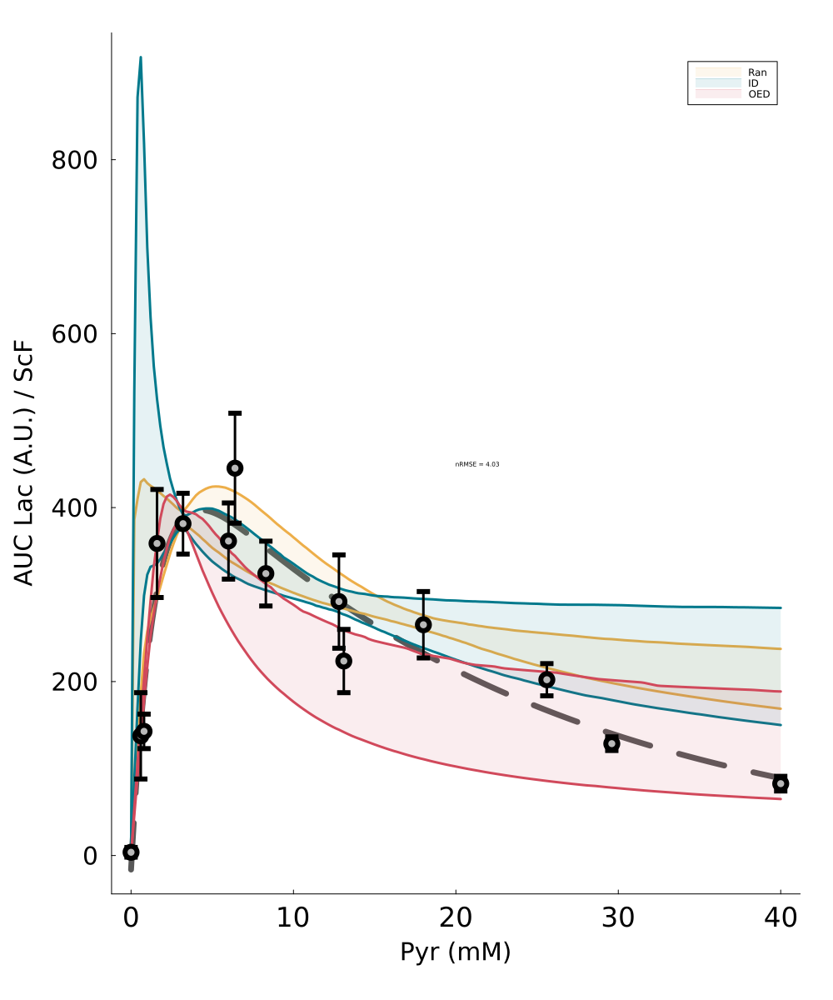

In [35]:
xx = zeros(length(cns)*3)
indd = collect(1:3:length(cns)*3)
for i in 1:length(cns)
    xx[indd[i]:indd[i]+2] .= cns[i]
end

yy = zeros(length(cns)*3)
indd = collect(1:3:length(cns)*3)
for i in 1:length(cns)
    yy[indd[i]:indd[i]+2] = aucs[i,:]
end

pp = [338,170,0.2024,-17,0.202847]

ss(t,p) = p[1].*(p[2].*exp.(-t.*p[3]).+p[4].*exp.(-t.*p[5]))

fit = LsqFit.curve_fit(ss, xx, yy, pp, maxIter=10000, x_tol = 1e-7, g_tol = 1e-7)


# nRMSE (Does not include the 0, since the low noise in that experiment has a really high effect, masking the rest of the experiments)
fftc = ss(cns, coef(fit))
nRMSE = sum(((mean((aucs), dims = 2)[2:end] - fftc[2:end]).^2) ./ std((aucs), dims = 2)[2:end].^2)/length(fftc[2:end]) + log(5*log(length(fftc[2:end])))


pp1 = plot(0:0.1:40, ss(0:0.1:40, coef(fit)), label="", colour="#595959ff", linewidth = 7,  linestyle = :dash)





ccpal = ["#edae49ff","#00798cff","#d1495bff"];

plot!(PyrCons4, lacSumQuantR2[1,:], label = "", color = ccpal[1],
    xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantR2[2,:], label = "", color = ccpal[1], linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantR2[2,:], fillrange=convert.(Float64, lacSumQuantR2[1,:]), color=ccpal[1], fillalpha=0.1, linewidth = 0, label = "Ran")


plot!(PyrCons4, lacSumQuantI2[1,:], label = "", color = ccpal[2],
    xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantI2[2,:], label = "", color = ccpal[2], linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantI2[2,:], fillrange=convert.(Float64, lacSumQuantI2[1,:]), color=ccpal[2], fillalpha=0.1, linewidth = 0, label = "ID")


plot!(PyrCons4, lacSumQuantO2[1,:], label = "", color = ccpal[3],
    xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantO2[2,:], label = "", color = ccpal[3], linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantO2[2,:], fillrange=convert.(Float64, lacSumQuantO2[1,:]), color=ccpal[3], fillalpha=0.1, linewidth = 0, label = "OED")


scatter!(cns, mean(aucs, dims = 2), yerror = std(aucs, dims = 2), label = "", grid = false, xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.) / ScF", width=3, 
        colour = "#b9b9b9ff", alpha = 1, size = (1000,1200), xtickfont=font(22), ytickfont=font(20), margins=8Plots.mm, guidefontsize = 20, markersize = 8, markerstrokewidth=3)

annotate!(20, 450, text("nRMSE = "*string(round(nRMSE, digits = 2)),  :black, :left, 5))



# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure5Stuff\\PyrVsLac1.svg")

display(pp1)

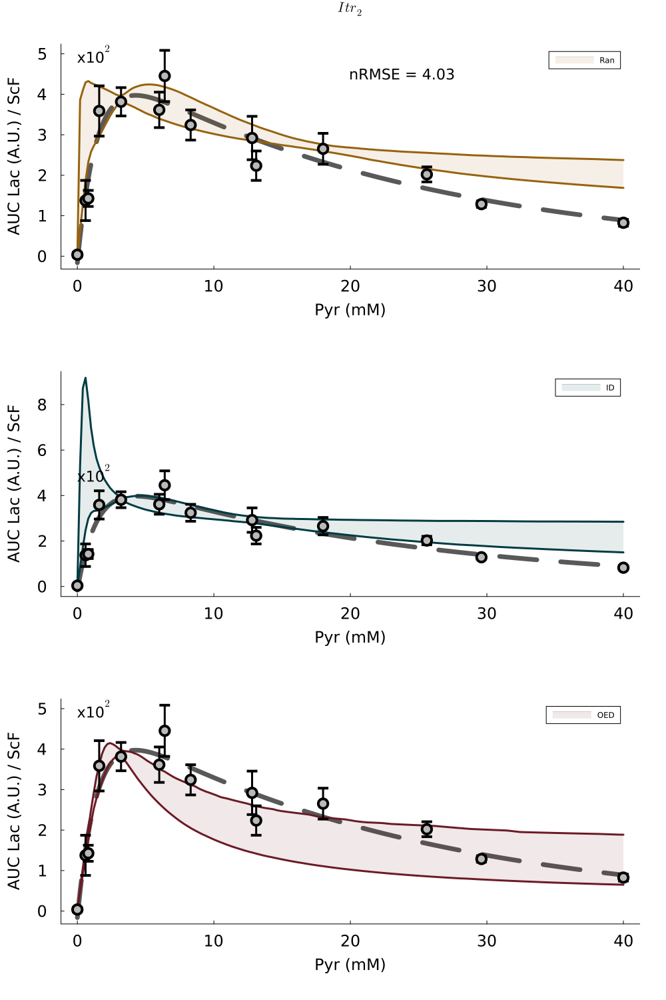

In [36]:
xx = zeros(length(cns)*3)
indd = collect(1:3:length(cns)*3)
for i in 1:length(cns)
    xx[indd[i]:indd[i]+2] .= cns[i]
end

yy = zeros(length(cns)*3)
indd = collect(1:3:length(cns)*3)
for i in 1:length(cns)
    yy[indd[i]:indd[i]+2] = aucs[i,:]
end

pp = [338,170,0.2024,-17,0.202847]

ss(t,p) = p[1].*(p[2].*exp.(-t.*p[3]).+p[4].*exp.(-t.*p[5]))

fit = LsqFit.curve_fit(ss, xx, yy, pp, maxIter=10000, x_tol = 1e-7, g_tol = 1e-7)


# nRMSE (Does not include the 0, since the low noise in that experiment has a really high effect, masking the rest of the experiments)
fftc = ss(cns, coef(fit))
nRMSE = sum(((mean((aucs), dims = 2)[2:end] - fftc[2:end]).^2) ./ std((aucs), dims = 2)[2:end].^2)/length(fftc[2:end]) + log(5*log(length(fftc[2:end])))


snt = 10^2
cntz = sum(split(string(snt), "") .== "0")

pp1 = plot(0:0.1:40, ss(0:0.1:40, coef(fit))./snt, label="", colour="#595959ff", linewidth = 7,  linestyle = :dash)

ccpal = ["#97630fff","#003c43ff","#6c1b26ff"];



plot!(PyrCons4, lacSumQuantR2[1,:]./snt, label = "", color = ccpal[1],
    xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantR2[2,:]./snt, label = "", color = ccpal[1], linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantR2[2,:]./snt, fillrange=convert.(Float64, lacSumQuantR2[1,:]./snt), color=ccpal[1], fillalpha=0.1, linewidth = 0, label = "Ran", title = L"Itr_2")

scatter!(cns, mean(aucs./snt, dims = 2), yerror = std(aucs./snt, dims = 2), label = "", grid = false, xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.) / ScF", width=3, 
        colour = "#b9b9b9ff", alpha = 1, size = (1000,400), xtickfont=font(16), ytickfont=font(16), margins=8Plots.mm, guidefontsize = 16, markersize = 8, markerstrokewidth=2)

annotate!(0, 5, text("x10"*L"^2",  :black, :left, 15))

annotate!(20, 450 ./snt, text("nRMSE = "*string(round(nRMSE, digits = 2)),  :black, :left, 15))



pp2 = plot(0:0.1:40, ss(0:0.1:40, coef(fit))./snt, label="", colour="#595959ff", linewidth = 7,  linestyle = :dash)

# ccpal = ["#edae49ff","#00798cff","#d1495bff"];

plot!(PyrCons4, lacSumQuantI2[1,:]./snt, label = "", color = ccpal[2],
    xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantI2[2,:]./snt, label = "", color = ccpal[2], linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantI2[2,:]./snt, fillrange=convert.(Float64, lacSumQuantI2[1,:]./snt), color=ccpal[2], fillalpha=0.1, linewidth = 0, label = "ID")

scatter!(cns, mean(aucs./snt, dims = 2), yerror = std(aucs./snt, dims = 2), label = "", grid = false, xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.) / ScF", width=3, 
        colour = "#b9b9b9ff", alpha = 1, size = (1000,400), xtickfont=font(16), ytickfont=font(16), margins=8Plots.mm, guidefontsize = 16, markersize = 8, markerstrokewidth=2)
annotate!(0, 5, text("x10"*L"^2",  :black, :left, 15))


pp3 = plot(0:0.1:40, ss(0:0.1:40, coef(fit))./snt, label="", colour="#595959ff", linewidth = 7,  linestyle = :dash)

# ccpal = ["#edae49ff","#00798cff","#d1495bff"];

plot!(PyrCons4, lacSumQuantO2[1,:]./snt, label = "", color = ccpal[3],
    xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantO2[2,:]./snt, label = "", color = ccpal[3], linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantO2[2,:]./snt, fillrange=convert.(Float64, lacSumQuantO2[1,:]./snt), color=ccpal[3], fillalpha=0.1, linewidth = 0, label = "OED")

scatter!(cns, mean(aucs./snt, dims = 2), yerror = std(aucs./snt, dims = 2), label = "", grid = false, xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.) / ScF", width=3, 
        colour = "#b9b9b9ff", alpha = 1, size = (1000,400), xtickfont=font(16), ytickfont=font(16), margins=8Plots.mm, guidefontsize = 16, markersize = 8, markerstrokewidth=2)
annotate!(0, 5, text("x10"*L"^2",  :black, :left, 15))

# plot!(PyrCons4, lacSumQuantI2[1,:], label = "", color = ccpal[2],
#     xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1)
# plot!(PyrCons4, lacSumQuantI2[2,:], label = "", color = ccpal[2], linewidth=3, alpha = 1)
# plot!(PyrCons4, lacSumQuantI2[2,:], fillrange=convert.(Float64, lacSumQuantI2[1,:]), color=ccpal[2], fillalpha=0.1, linewidth = 0, label = "ID")



PPP = plot(pp1,pp2,pp3, layout=(3,1), size = (1000,1500))



# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure5Stuff\\PyrVsLac1_Split.svg")

display(PPP)

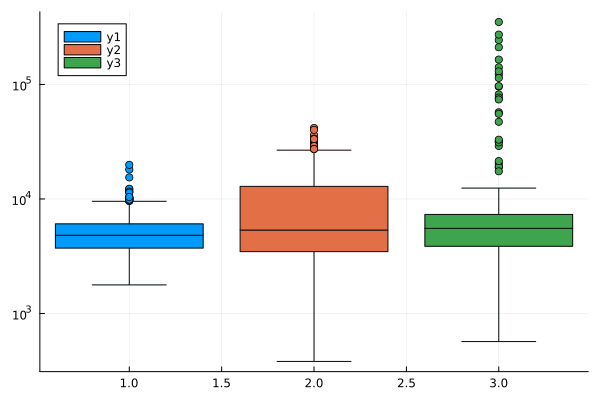

In [152]:
MSE_R2 = [sum((sumSimsR2[i,:]-ss(0:disc2:40, coef(fit))).^2)/length(sumSimsR2[i,:]) for i in 1:size(sumSimsR2)[1]];
MSE_I2 = [sum((sumSimsI2[i,:]-ss(0:disc2:40, coef(fit))).^2)/length(sumSimsI2[i,:]) for i in 1:size(sumSimsI2)[1]];
MSE_O2 = [sum((sumSimsO2[i,:]-ss(0:disc2:40, coef(fit))).^2)/length(sumSimsO2[i,:]) for i in 1:size(sumSimsO2)[1]];

boxplot([MSE_R2, MSE_I2, MSE_O2], yscale=:log10)

#### Figure Iteration 3

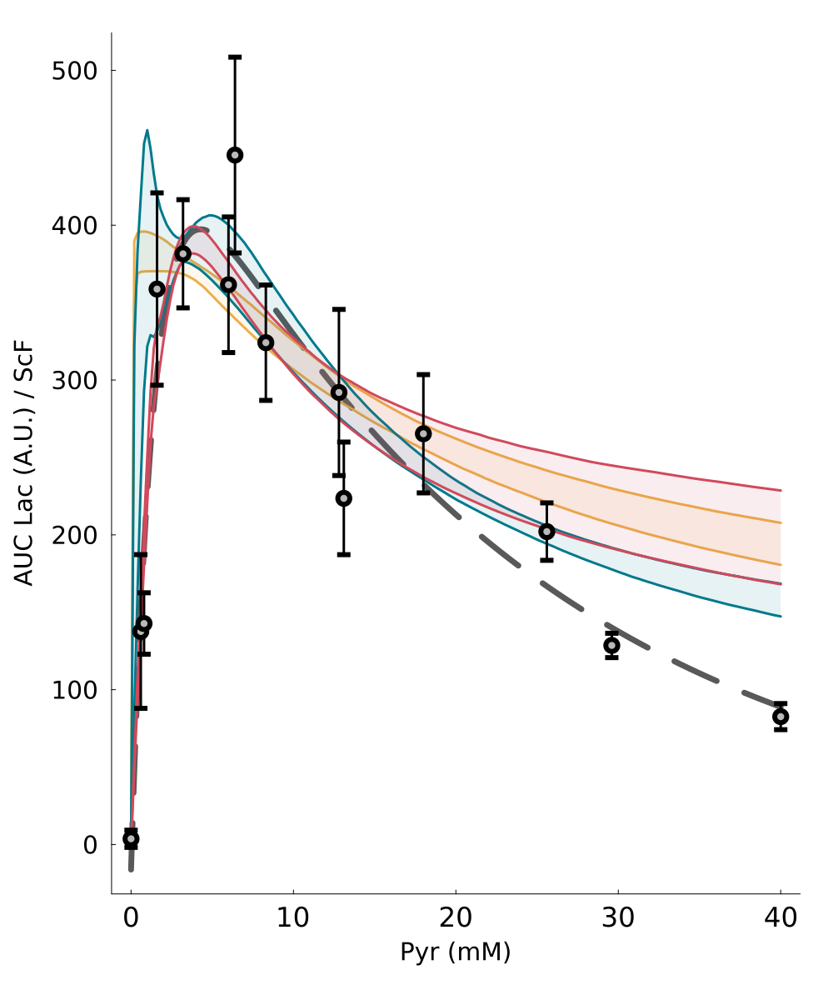

In [37]:
xx = zeros(length(cns)*3)
indd = collect(1:3:length(cns)*3)
for i in 1:length(cns)
    xx[indd[i]:indd[i]+2] .= cns[i]
end

yy = zeros(length(cns)*3)
indd = collect(1:3:length(cns)*3)
for i in 1:length(cns)
    yy[indd[i]:indd[i]+2] = aucs[i,:]
end

pp = [338,170,0.2024,-17,0.202847]

ss(t,p) = p[1].*(p[2].*exp.(-t.*p[3]).+p[4].*exp.(-t.*p[5]))

fit = LsqFit.curve_fit(ss, xx, yy, pp, maxIter=10000, x_tol = 1e-7, g_tol = 1e-7)




# pp1 = plot(0:0.1:40, ss(0:0.1:40, coef(fit)), label="", colour="#5be0d0ff", linewidth = 7, ylim = (-0.5, maximum(yy).+(maximum(yy)*0.1)))

# scatter!(cns, mean(aucs, dims = 2), yerror = std(aucs, dims = 2), label = "", grid = false, xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.) / ScF", width=3, 
#         colour = "#e05b5fff", alpha = 1, size = (1000,700), xtickfont=font(22), ytickfont=font(20), margins=8Plots.mm, guidefontsize = 20, markersize = 8, markerstrokewidth=3)


pp1 = plot(0:0.1:40, ss(0:0.1:40, coef(fit)), label="", colour="#595959ff", linewidth = 7,   linestyle = :dash)


ccpal = ["#edae49ff","#00798cff","#d1495bff"];

plot!(PyrCons4, lacSumQuantR3[1,:], label = "", color = ccpal[1],
    xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantR3[2,:], label = "", color = ccpal[1], linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantR3[2,:], fillrange=convert.(Float64, lacSumQuantR3[1,:]), color=ccpal[1], fillalpha=0.1, linewidth = 0, label = "")


plot!(PyrCons4, lacSumQuantI3[1,:], label = "", color = ccpal[2],
    xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantI3[2,:], label = "", color = ccpal[2], linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantI3[2,:], fillrange=convert.(Float64, lacSumQuantI3[1,:]), color=ccpal[2], fillalpha=0.1, linewidth = 0, label = "")


plot!(PyrCons4, lacSumQuantO3[1,:], label = "", color = ccpal[3],
    xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantO3[2,:], label = "", color = ccpal[3], linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantO3[2,:], fillrange=convert.(Float64, lacSumQuantO3[1,:]), color=ccpal[3], fillalpha=0.1, linewidth = 0, label = "")


scatter!(cns, mean(aucs, dims = 2), yerror = std(aucs, dims = 2), label = "", grid = false, xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.) / ScF", width=3, 
        colour = "#b9b9b9ff", alpha = 1, size = (1000,1200), xtickfont=font(22), ytickfont=font(20), margins=8Plots.mm, guidefontsize = 20, markersize = 8, markerstrokewidth=3)


# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure5Stuff\\PyrVsLac2.svg")

display(pp1)

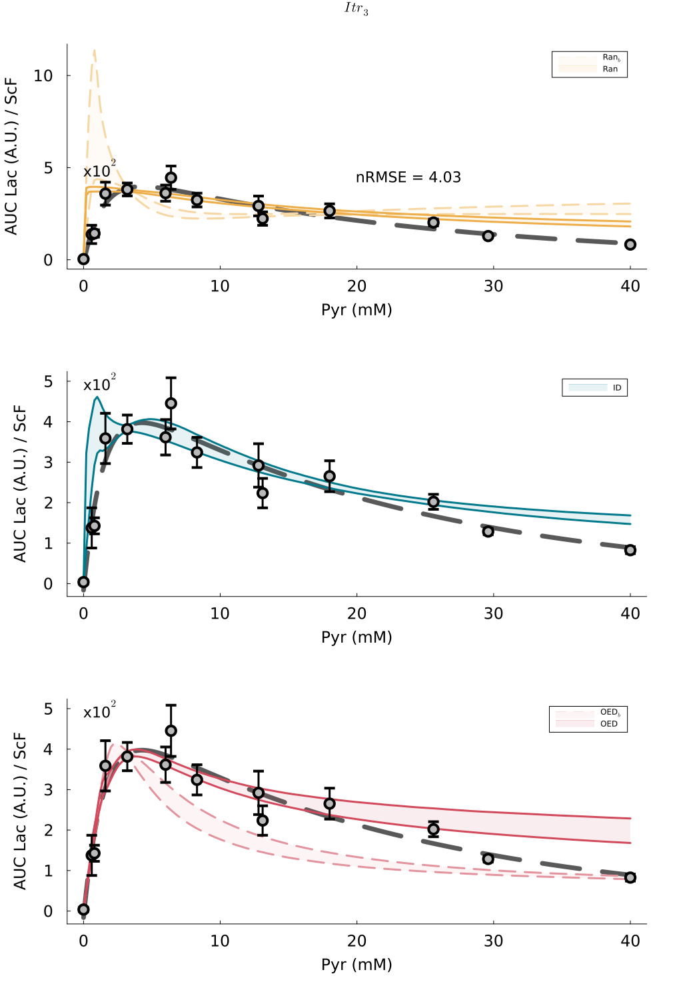

In [38]:
xx = zeros(length(cns)*3)
indd = collect(1:3:length(cns)*3)
for i in 1:length(cns)
    xx[indd[i]:indd[i]+2] .= cns[i]
end

yy = zeros(length(cns)*3)
indd = collect(1:3:length(cns)*3)
for i in 1:length(cns)
    yy[indd[i]:indd[i]+2] = aucs[i,:]
end

pp = [338,170,0.2024,-17,0.202847]

ss(t,p) = p[1].*(p[2].*exp.(-t.*p[3]).+p[4].*exp.(-t.*p[5]))

fit = LsqFit.curve_fit(ss, xx, yy, pp, maxIter=10000, x_tol = 1e-7, g_tol = 1e-7)


# nRMSE (Does not include the 0, since the low noise in that experiment has a really high effect, masking the rest of the experiments)
fftc = ss(cns, coef(fit))
nRMSE = sum(((mean((aucs), dims = 2)[2:end] - fftc[2:end]).^2) ./ std((aucs), dims = 2)[2:end].^2)/length(fftc[2:end]) + log(5*log(length(fftc[2:end])))

snt = 10^2
cntz = sum(split(string(snt), "") .== "0")

pp1 = plot(0:0.1:40, ss(0:0.1:40, coef(fit))./snt, label="", colour="#595959ff", linewidth = 7,  linestyle = :dash)

ccpal = ["#edae49ff","#00798cff","#d1495bff"];




plot!(PyrCons4, lacSumQuantR3b[1,:]./snt, label = "", color = "#f6d7a4ff",
    xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1, linestyle=:dash)
plot!(PyrCons4, lacSumQuantR3b[2,:]./snt, label = "", color = "#f6d7a4ff", linewidth=3, alpha = 1, linestyle=:dash)
plot!(PyrCons4, lacSumQuantR3b[2,:]./snt, fillrange=convert.(Float64, lacSumQuantR3b[1,:]./snt), color="#f6d7a4ff", fillalpha=0.1, linewidth = 0, label = "Ran"*L"_b", title = L"Itr_3", linestyle=:dash)


plot!(PyrCons4, lacSumQuantR3[1,:]./snt, label = "", color = ccpal[1],
    xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantR3[2,:]./snt, label = "", color = ccpal[1], linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantR3[2,:]./snt, fillrange=convert.(Float64, lacSumQuantR3[1,:]./snt), color=ccpal[1], fillalpha=0.1, linewidth = 0, label = "Ran", title = L"Itr_3",
yticks = [0,5,10])


scatter!(cns, mean(aucs./snt, dims = 2), yerror = std(aucs./snt, dims = 2), label = "", grid = false, xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.) / ScF", width=3, 
        colour = "#b9b9b9ff", alpha = 1, size = (1000,400), xtickfont=font(16), ytickfont=font(16), margins=8Plots.mm, guidefontsize = 16, markersize = 8, markerstrokewidth=2)

annotate!(0, 5, text("x10"*L"^2",  :black, :left, 15))

annotate!(20, 450 ./snt, text("nRMSE = "*string(round(nRMSE, digits = 2)),  :black, :left, 15))



pp2 = plot(0:0.1:40, ss(0:0.1:40, coef(fit))./snt, label="", colour="#595959ff", linewidth = 7,  linestyle = :dash)

ccpal = ["#edae49ff","#00798cff","#d1495bff"];

plot!(PyrCons4, lacSumQuantI3[1,:]./snt, label = "", color = ccpal[2],
    xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantI3[2,:]./snt, label = "", color = ccpal[2], linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantI3[2,:]./snt, fillrange=convert.(Float64, lacSumQuantI3[1,:]./snt), color=ccpal[2], fillalpha=0.1, linewidth = 0, label = "ID")

scatter!(cns, mean(aucs./snt, dims = 2), yerror = std(aucs./snt, dims = 2), label = "", grid = false, xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.) / ScF", width=3, 
        colour = "#b9b9b9ff", alpha = 1, size = (1000,400), xtickfont=font(16), ytickfont=font(16), margins=8Plots.mm, guidefontsize = 16, markersize = 8, markerstrokewidth=2)
annotate!(0, 5, text("x10"*L"^2",  :black, :left, 15))


pp3 = plot(0:0.1:40, ss(0:0.1:40, coef(fit))./snt, label="", colour="#595959ff", linewidth = 7,  linestyle = :dash)

ccpal = ["#edae49ff","#00798cff","#d1495bff"];

plot!(PyrCons4, lacSumQuantO3b[1,:]./snt, label = "", color = "#e3939dff",
    xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1, linestyle=:dash)
plot!(PyrCons4, lacSumQuantO3b[2,:]./snt, label = "", color = "#e3939dff", linewidth=3, alpha = 1, linestyle=:dash)
plot!(PyrCons4, lacSumQuantO3b[2,:]./snt, fillrange=convert.(Float64, lacSumQuantO3b[1,:]./snt), color="#e3939dff", fillalpha=0.1, linewidth = 0, label = "OED"*L"_b", linestyle=:dash)


plot!(PyrCons4, lacSumQuantO3[1,:]./snt, label = "", color = ccpal[3],
    xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantO3[2,:]./snt, label = "", color = ccpal[3], linewidth=3, alpha = 1)
plot!(PyrCons4, lacSumQuantO3[2,:]./snt, fillrange=convert.(Float64, lacSumQuantO3[1,:]./snt), color=ccpal[3], fillalpha=0.1, linewidth = 0, label = "OED")

scatter!(cns, mean(aucs./snt, dims = 2), yerror = std(aucs./snt, dims = 2), label = "", grid = false, xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.) / ScF", width=3, 
        colour = "#b9b9b9ff", alpha = 1, size = (1000,400), xtickfont=font(16), ytickfont=font(16), margins=8Plots.mm, guidefontsize = 16, markersize = 8, markerstrokewidth=2)
annotate!(0, 5, text("x10"*L"^2",  :black, :left, 15))

# plot!(PyrCons4, lacSumQuantI2[1,:], label = "", color = ccpal[2],
#     xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1)
# plot!(PyrCons4, lacSumQuantI2[2,:], label = "", color = ccpal[2], linewidth=3, alpha = 1)
# plot!(PyrCons4, lacSumQuantI2[2,:], fillrange=convert.(Float64, lacSumQuantI2[1,:]), color=ccpal[2], fillalpha=0.1, linewidth = 0, label = "ID")



PPP = plot(pp1,pp2,pp3, layout=(3,1), size = (1010,1500))



# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure5Stuff\\PyrVsLac2_Split.svg")

display(PPP)

#### Figure Iteration 3 OED

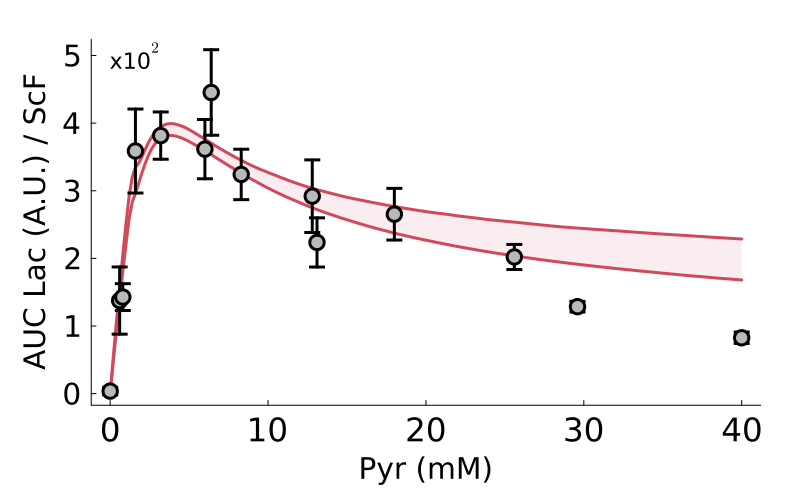

In [51]:
xx = zeros(length(cns)*3)
indd = collect(1:3:length(cns)*3)
for i in 1:length(cns)
    xx[indd[i]:indd[i]+2] .= cns[i]
end

yy = zeros(length(cns)*3)
indd = collect(1:3:length(cns)*3)
for i in 1:length(cns)
    yy[indd[i]:indd[i]+2] = aucs[i,:]
end

pp = [338,170,0.2024,-17,0.202847]

ss(t,p) = p[1].*(p[2].*exp.(-t.*p[3]).+p[4].*exp.(-t.*p[5]))

fit = LsqFit.curve_fit(ss, xx, yy, pp, maxIter=10000, x_tol = 1e-7, g_tol = 1e-7)


snt = 10^2

ccpal = ["#edae49ff","#00798cff","#d1495bff", "#7a2490ff"];

pp1 = plot(PyrCons5, lacSumQuantO3[1,:]./snt, label = "", color = ccpal[3],
    xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1)
plot!(PyrCons5, lacSumQuantO3[2,:]./snt, label = "", color = ccpal[3], linewidth=3, alpha = 1)
plot!(PyrCons5, lacSumQuantO3[2,:]./snt, fillrange=convert.(Float64, lacSumQuantO3[1,:]./snt), color=ccpal[3], fillalpha=0.1, linewidth = 0, label = "")

scatter!(cns, mean(aucs./snt, dims = 2), yerror = std(aucs./snt, dims = 2), label = "", grid = false, xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.) / ScF", width=3, 
        colour = "#b9b9b9ff", alpha = 1, size = (800,500), xtickfont=font(22), ytickfont=font(20), margins=8Plots.mm, guidefontsize = 20, markersize = 8, markerstrokewidth=3)

annotate!(0, 5, text("x10"*L"^2",  :black, :left, 15))


savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure5Stuff\\PyrVsLacItr3.svg")

display(pp1)

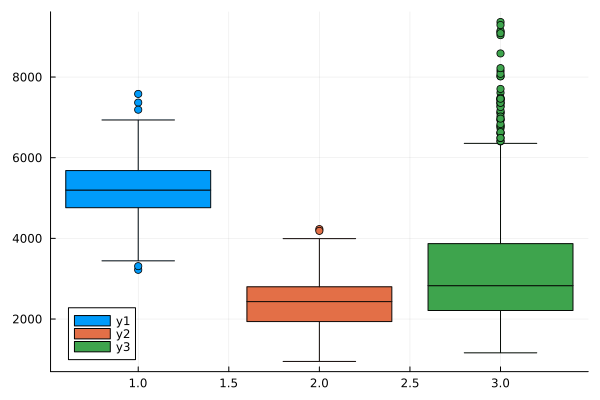

In [157]:
MSE_R3 = [sum((sumSimsR3[i,:]-ss(0:disc2:40, coef(fit))).^2)/length(sumSimsR3[i,:]) for i in 1:size(sumSimsR3)[1]];
MSE_I3 = [sum((sumSimsI3[i,:]-ss(0:disc2:40, coef(fit))).^2)/length(sumSimsI3[i,:]) for i in 1:size(sumSimsI3)[1]];
MSE_O3 = [sum((sumSimsO3[i,:]-ss(0:disc2:40, coef(fit))).^2)/length(sumSimsO3[i,:]) for i in 1:size(sumSimsO3)[1]];

boxplot([MSE_R3, MSE_I3, MSE_O3])

##### Compute Euclidean Distance Average to Fit Curve

In [52]:
xx = zeros(length(cns)*3)
indd = collect(1:3:length(cns)*3)
for i in 1:length(cns)
    xx[indd[i]:indd[i]+2] .= cns[i]
end

yy = zeros(length(cns)*3)
indd = collect(1:3:length(cns)*3)
for i in 1:length(cns)
    yy[indd[i]:indd[i]+2] = aucs[i,:]
end

pp = [338,170,0.2024,-17,0.202847]

ss(t,p) = p[1].*(p[2].*exp.(-t.*p[3]).+p[4].*exp.(-t.*p[5]))

fit = LsqFit.curve_fit(ss, xx, yy, pp, maxIter=10000, x_tol = 1e-7, g_tol = 1e-7)


# nRMSE (Does not include the 0, since the low noise in that experiment has a really high effect, masking the rest of the experiments)
fftcSC = ss(collect(0:0.2:40), coef(fit))



# SimsAll = [posterSimsR2, posterSimsI2, posterSimsO2, posterSimsR3, posterSimsR3b, posterSimsI3, posterSimsO3, posterSimsO3b];
# labsSA = ["Ran\nItr"*L"_2","ID\nItr"*L"_2","OED\nItr"*L"_2","Ran\nItr"*L"_3","Ran\nItr"*L"_3^b","ID\nItr"*L"_3","OED\nItr"*L"_3","OED\nItr"*L"_3^b"]

SimsAll = [posterSimsR2, posterSimsR3, posterSimsR3b, posterSimsI2, posterSimsI3, posterSimsO2, posterSimsO3, posterSimsO3b, posterSimsO4,
            posterSimsO3b];
labsSA = ["Itr"*L"_2","Itr"*L"_3","Itr"*L"_3^b","Itr"*L"_2","Itr"*L"_3","Itr"*L"_2","Itr"*L"_3","Itr"*L"_3^b","Itr"*L"_4","Itr"*L"_5"]

AllInt = zeros(length(SimsAll), length(fftcSC), size(posterSimsR2[1])[3])

k = 1 # Posterior
i = 2 # Pyr Concentration
j = 8 # Sample

for k in 1:length(SimsAll)
    for i in 1:length(fftcSC)
        for j in 1:size(posterSimsR2[1])[3]
            AllInt[k, i,j] = trapz(collect(0:5:395), SimsAll[k][i][:,13,j])
        end
    end
end

AllEucDis = zeros(length(SimsAll), length(fftcSC)-1, size(posterSimsR2[1])[3])

for k in 1:length(SimsAll)
    for j in 1:size(posterSimsR2[1])[3]
        AllEucDis[k, :,j] = sqrt.((AllInt[k,:,j][2:end] - fftcSC[2:end]).^2)
    end
end

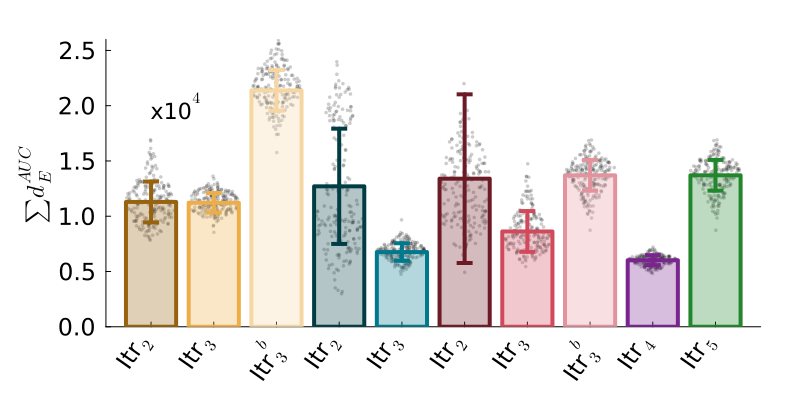

In [53]:
Random.seed!(8798534)
indsp = StatsBase.sample(1:size(AllEucDis)[3], 200, replace = false)

ppss1 = dotplot(transpose(1:length(SimsAll)), transpose(reshape(sum(AllEucDis, dims = 2), size(AllEucDis)[1], size(AllEucDis)[3])[:,indsp])./10^4, label = "",
        colour = "black", alpha = 0.2, markersize = 2)

bar!(transpose(1:length(SimsAll)), transpose(reshape(mean(sum(AllEucDis, dims = 2), dims = 3), length(SimsAll)))./10^4, 
    yerror = transpose(reshape(std(sum(AllEucDis, dims = 2), dims = 3), length(SimsAll)))./10^4, 

    label = "", grid = false, xticks = (transpose([1:length(SimsAll)]), reshape(labsSA, length(labsSA), 1)),
    colour = ["#97630fff" "#edae49ff" "#f6d7a4ff" "#003c43ff" "#00798cff" "#6c1b26ff" "#d1495bff" "#e3939dff" "#7a2490ff" "#22862dff"],
    markercolour = ["#97630fff" "#edae49ff" "#f6d7a4ff" "#003c43ff" "#00798cff" "#6c1b26ff" "#d1495bff" "#e3939dff" "#7a2490ff" "#22862dff"],
    linecolour = ["#97630fff" "#edae49ff" "#f6d7a4ff" "#003c43ff" "#00798cff" "#6c1b26ff" "#d1495bff" "#e3939dff" "#7a2490ff" "#22862dff"],
    linewidth=4, markersize = 8, fillalpha=0.3,
    ylabel = L"\sum d_E^{AUC}", ylim = (0,2.6), xrotation =55,
    size = (800,400), xtickfont=font(16), ytickfont=font(16), margins=8Plots.mm, guidefontsize = 16, markerstrokewidth=2)

annotate!(1, 2, text("x10"*L"^4",  :black, :left, 15))


# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\EuclDists.svg")

display(ppss1)

1000

# BIC Data

In [54]:
resi = false
mainP = "C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\ResultsPostAnal\\"

if resi == true
    println(1)
    randSimsP = Array{Any}(undef, length(datsD))
    indrSimsP = Array{Any}(undef, length(datsD))
    boedSimsP = Array{Any}(undef, length(datsD))

    randSimsA = Array{Any}(undef, length(datsD))
    randSimsAb = Array{Any}(undef, length(datsD))
    indrSimsA = Array{Any}(undef, length(datsD))
    boedSimsA = Array{Any}(undef, length(datsD))
    boedSimsAb = Array{Any}(undef, length(datsD))
    finaSimsA = Array{Any}(undef, length(datsD))
    fin2SimsA = Array{Any}(undef, length(datsD))
    for i in 2:length(datsD)
        expS = datsD[i]
        PyrCons = [cns[i]]
        nSamps = 8000
        randSimsP[i] = simDwnExp(expS, datsD, PyrCons, nSamps, posterR2, allD, false)
        indrSimsP[i] = simDwnExp(expS, datsD, PyrCons, nSamps, posterI2, allD, false)
        boedSimsP[i] = simDwnExp(expS, datsD, PyrCons, nSamps, posterO2, allD, false)

        randSimsA[i] = simDwnExp(expS, datsD, PyrCons, nSamps, posterR3, allD, false)
        randSimsAb[i] = simDwnExp(expS, datsD, PyrCons, nSamps, posterR3b, allD, false)
        indrSimsA[i] = simDwnExp(expS, datsD, PyrCons, nSamps, posterI3, allD, false)
        boedSimsA[i] = simDwnExp(expS, datsD, PyrCons, nSamps, posterO3, allD, false)
        boedSimsAb[i] = simDwnExp(expS, datsD, PyrCons, nSamps, posterO3b, allD, false)

        finaSimsA[i] = simDwnExp(expS, datsD, PyrCons, nSamps, posterO4, allD, false)

        fin2SimsA[i] = simDwnExp(expS, datsD, PyrCons, nSamps, posterO5, allD, false)
    end
    JLD2.save(mainP*"SimulationsPosteriorExpers_Ran2.jld", "randSimsP", randSimsP);
    JLD2.save(mainP*"SimulationsPosteriorExpers_ID2.jld", "indrSimsP", indrSimsP);
    JLD2.save(mainP*"SimulationsPosteriorExpers_OED2.jld", "boedSimsP", boedSimsP);

    JLD2.save(mainP*"SimulationsPosteriorExpers_Ran3.jld", "randSimsA", randSimsA);
    JLD2.save(mainP*"SimulationsPosteriorExpers_Ran3b.jld", "randSimsAb", randSimsAb);
    JLD2.save(mainP*"SimulationsPosteriorExpers_ID3.jld", "indrSimsA", indrSimsA);
    JLD2.save(mainP*"SimulationsPosteriorExpers_OED3.jld", "boedSimsA", boedSimsA);
    JLD2.save(mainP*"SimulationsPosteriorExpers_OED3b.jld", "boedSimsAb", boedSimsAb);

    JLD2.save(mainP*"SimulationsPosteriorExpers_Fin4.jld", "finaSimsA", finaSimsA);

    JLD2.save(mainP*"SimulationsPosteriorExpers_Fin5.jld", "fin2SimsA", fin2SimsA);
else
    println(2)
    randSimsP = JLD2.load(mainP*"SimulationsPosteriorExpers_Ran2.jld")["randSimsP"];
    indrSimsP = JLD2.load(mainP*"SimulationsPosteriorExpers_ID2.jld")["indrSimsP"];
    boedSimsP = JLD2.load(mainP*"SimulationsPosteriorExpers_OED2.jld")["boedSimsP"];

    randSimsA = JLD2.load(mainP*"SimulationsPosteriorExpers_Ran3.jld")["randSimsA"];
    randSimsAb = JLD2.load(mainP*"SimulationsPosteriorExpers_Ran3b.jld")["randSimsAb"];
    indrSimsA = JLD2.load(mainP*"SimulationsPosteriorExpers_ID3.jld")["indrSimsA"];
    boedSimsA = JLD2.load(mainP*"SimulationsPosteriorExpers_OED3.jld")["boedSimsA"];
    boedSimsAb = JLD2.load(mainP*"SimulationsPosteriorExpers_OED3b.jld")["boedSimsAb"];

    finaSimsA = JLD2.load(mainP*"SimulationsPosteriorExpers_Fin4.jld")["finaSimsA"];

    fin2SimsA = JLD2.load(mainP*"SimulationsPosteriorExpers_Fin5.jld")["fin2SimsA"];
end

2


14-element Vector{Any}:
 #undef
    (Any[[600.0 0.0 … 0.0 1226.1469685352254; 561.7731693794557 0.4433794932182283 … 1.019166750794777 1111.0957207747078; … ; 3.532736072127677 0.011659421139191703 … 0.45287724938881857 -0.26439951759407126; 3.3076605668362173 0.011308210106335275 … 0.434634637114825 -0.2824087194305043;;;], [600.0 0.0 … 0.0 1226.1469685352254; 558.8095152342817 0.4376746028249293 … 1.0237840092011805 1111.0959186824118; … ; 2.338457822585301 0.006148332988787495 … 0.27958633427271395 0.08548901449414012; 2.177920804235104 0.005836081379170063 … 0.2631070924152103 0.05973162124498146;;;], [600.0 0.0 … 0.0 1226.1469685352254; 562.341409250554 0.42574959070469925 … 0.9597169784298629 1111.16435729822; … ; 3.8225993828062674 0.007041319183665892 … 0.40777431013690474 -0.008717095002233489; 3.582676540068661 0.006636811287993103 … 0.3834631485622077 -0.0292189115398618;;;], [600.0 0.0 … 0.0 1226.1469685352254; 556.21013039439 0.30189899921070557 … 1.1419344406977874 1110.9

In [55]:
tsC2 = vcat(collect(0:5:395));

In [56]:
# i = 2 to number of experiments
# j = 1 to total number of samples
i=2
BIC_Lac_R1 = zeros(length(datsD), length(randSimsP[i][1]))
BIC_Lac_I1 = zeros(length(datsD), length(indrSimsP[i][1]))
BIC_Lac_O1 = zeros(length(datsD), length(boedSimsP[i][1]))

BIC_Lac_R = zeros(length(datsD), length(randSimsA[i][1]))
BIC_Lac_Rb = zeros(length(datsD), length(randSimsAb[i][1]))
BIC_Lac_I = zeros(length(datsD), length(indrSimsA[i][1]))
BIC_Lac_O = zeros(length(datsD), length(boedSimsA[i][1]))
BIC_Lac_Ob = zeros(length(datsD), length(boedSimsAb[i][1]))

BIC_Lac_F = zeros(length(datsD), length(finaSimsA[i][1]))

BIC_Lac_F2 = zeros(length(datsD), length(fin2SimsA[i][1]))


nRMSE_Lac_R1 = zeros(length(datsD), length(randSimsP[i][1]))
nRMSE_Lac_I1 = zeros(length(datsD), length(indrSimsP[i][1]))
nRMSE_Lac_O1 = zeros(length(datsD), length(boedSimsP[i][1]))

nRMSE_Lac_R = zeros(length(datsD), length(randSimsA[i][1]))
nRMSE_Lac_Rb = zeros(length(datsD), length(randSimsAb[i][1]))
nRMSE_Lac_I = zeros(length(datsD), length(indrSimsA[i][1]))
nRMSE_Lac_O = zeros(length(datsD), length(boedSimsA[i][1]))
nRMSE_Lac_Ob = zeros(length(datsD), length(boedSimsAb[i][1]))

nRMSE_Lac_F = zeros(length(datsD), length(finaSimsA[i][1]))

nRMSE_Lac_F2 = zeros(length(datsD), length(fin2SimsA[i][1]))

for i in 2:length(datsD)
    indDat = zeros(length(allD[i][:,1]))
    tmp = 1
    for m in 1:length(tsC2)
        if tsC2[m] in allD[i][:,1]
            indDat[tmp] = m
            tmp += 1
        end
    end
    indDat = convert.(Int, indDat);

    for j in 1:length(randSimsA[i][1])
        BIC_Lac_R1[i,j] = sum((((randSimsP[i][1][j][:,13,1][indDat].-allD[i][:,4]).^2)./allD[i][:,5].^2)) .+ (11*log(length(indDat)))
        BIC_Lac_I1[i,j] = sum((((indrSimsP[i][1][j][:,13,1][indDat].-allD[i][:,4]).^2)./allD[i][:,5].^2)) .+ (11*log(length(indDat)))
        BIC_Lac_O1[i,j] = sum((((boedSimsP[i][1][j][:,13,1][indDat].-allD[i][:,4]).^2)./allD[i][:,5].^2)) .+ (11*log(length(indDat)))

        BIC_Lac_R[i,j] = sum((((randSimsA[i][1][j][:,13,1][indDat].-allD[i][:,4]).^2)./allD[i][:,5].^2)) .+ (11*log(length(indDat)))
        BIC_Lac_Rb[i,j] = sum((((randSimsAb[i][1][j][:,13,1][indDat].-allD[i][:,4]).^2)./allD[i][:,5].^2)) .+ (11*log(length(indDat)))
        BIC_Lac_I[i,j] = sum((((indrSimsA[i][1][j][:,13,1][indDat].-allD[i][:,4]).^2)./allD[i][:,5].^2)) .+ (11*log(length(indDat)))
        BIC_Lac_O[i,j] = sum((((boedSimsA[i][1][j][:,13,1][indDat].-allD[i][:,4]).^2)./allD[i][:,5].^2)) .+ (11*log(length(indDat)))
        BIC_Lac_Ob[i,j] = sum((((boedSimsAb[i][1][j][:,13,1][indDat].-allD[i][:,4]).^2)./allD[i][:,5].^2)) .+ (11*log(length(indDat)))

        BIC_Lac_F[i,j] = sum((((finaSimsA[i][1][j][:,13,1][indDat].-allD[i][:,4]).^2)./allD[i][:,5].^2)) .+ (11*log(length(indDat)))

        BIC_Lac_F2[i,j] = sum((((fin2SimsA[i][1][j][:,13,1][indDat].-allD[i][:,4]).^2)./allD[i][:,5].^2)) .+ (11*log(length(indDat)))

        nRMSE_Lac_R1[i,j] = sqrt(sum((((randSimsP[i][1][j][:,13,1][indDat].-allD[i][:,4]).^2)./allD[i][:,5].^2))/length(indDat)) .+ (log(11*log(length(indDat))))
        nRMSE_Lac_I1[i,j] = sqrt(sum((((indrSimsP[i][1][j][:,13,1][indDat].-allD[i][:,4]).^2)./allD[i][:,5].^2))/length(indDat)) .+ (log(11*log(length(indDat))))
        nRMSE_Lac_O1[i,j] = sqrt(sum((((boedSimsP[i][1][j][:,13,1][indDat].-allD[i][:,4]).^2)./allD[i][:,5].^2))/length(indDat)) .+ (log(11*log(length(indDat))))

        nRMSE_Lac_R[i,j] = sqrt(sum((((randSimsA[i][1][j][:,13,1][indDat].-allD[i][:,4]).^2)./allD[i][:,5].^2))/length(indDat)) .+ (log(11*log(length(indDat))))
        nRMSE_Lac_Rb[i,j] = sqrt(sum((((randSimsAb[i][1][j][:,13,1][indDat].-allD[i][:,4]).^2)./allD[i][:,5].^2))/length(indDat)) .+ (log(11*log(length(indDat))))
        nRMSE_Lac_I[i,j] = sqrt(sum((((indrSimsA[i][1][j][:,13,1][indDat].-allD[i][:,4]).^2)./allD[i][:,5].^2))/length(indDat)) .+ (log(11*log(length(indDat))))
        nRMSE_Lac_O[i,j] = sqrt(sum((((boedSimsA[i][1][j][:,13,1][indDat].-allD[i][:,4]).^2)./allD[i][:,5].^2))/length(indDat)) .+ (log(11*log(length(indDat))))
        nRMSE_Lac_Ob[i,j] = sqrt(sum((((boedSimsAb[i][1][j][:,13,1][indDat].-allD[i][:,4]).^2)./allD[i][:,5].^2))/length(indDat)) .+ (log(11*log(length(indDat))))

        nRMSE_Lac_F[i,j] = sqrt(sum((((finaSimsA[i][1][j][:,13,1][indDat].-allD[i][:,4]).^2)./allD[i][:,5].^2))/length(indDat)) .+ (log(11*log(length(indDat))))

        nRMSE_Lac_F2[i,j] = sqrt(sum((((fin2SimsA[i][1][j][:,13,1][indDat].-allD[i][:,4]).^2)./allD[i][:,5].^2))/length(indDat)) .+ (log(11*log(length(indDat))))
    end
end

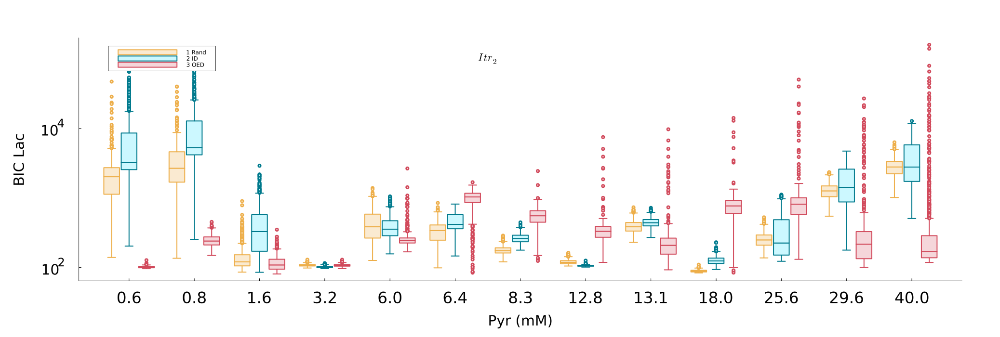

In [17]:
t = String[]
for i in 1:length(randSimsA[2][1][1:1000])
    push!(t,"1 Rand")
end
for i in 1:length(randSimsA[2][1][1:1000])
    push!(t,"2 ID")
end
for i in 1:length(randSimsA[2][1][1:1000])
    push!(t,"3 OED")
end

ca = repeat(t, length(cns)-1);


Random.seed!(164598464)

xa = String[]
for j in 1:length(cns)-1
    for i in 1:length(randSimsA[i][1][1:1000])*3
        push!(xa,string(cns[j+1]))
    end
end

va2b = []
for i in 1:length(cns)-1
    ttp = vcat(BIC_Lac_R1[2:end,:][:, StatsBase.sample(1:size(BIC_Lac_R1[2:end,:])[2], 1000, replace = false)][i,:], 
               BIC_Lac_I1[2:end,:][:, StatsBase.sample(1:size(BIC_Lac_R1[2:end,:])[2], 1000, replace = false)][i,:], 
               BIC_Lac_O1[2:end,:][:, StatsBase.sample(1:size(BIC_Lac_R1[2:end,:])[2], 1000, replace = false)][i,:])
    for j in 1:length(ttp)
    push!(va2b, ttp[j])
    end
end

va2 = []
for i in 1:length(cns)-1
    ttp = vcat(nRMSE_Lac_R1[2:end,:][:, StatsBase.sample(1:size(BIC_Lac_R1[2:end,:])[2], 1000, replace = false)][i,:], 
               nRMSE_Lac_I1[2:end,:][:, StatsBase.sample(1:size(BIC_Lac_R1[2:end,:])[2], 1000, replace = false)][i,:], 
               nRMSE_Lac_O1[2:end,:][:, StatsBase.sample(1:size(BIC_Lac_R1[2:end,:])[2], 1000, replace = false)][i,:])
    for j in 1:length(ttp)
    push!(va2, ttp[j])
    end
end

ss1 = groupedboxplot(xa, va2b, group = ca, yscale=:log10, grid = false, colour = ["#faead1ff" "#ccf8ffff" "#f5d6daff" "#efd6f5ff"], ylabel = "BIC Lac", xlabel = "Pyr (mM)", 
        size = (2075,700), xtickfont=font(22), ytickfont=font(20), margins=18Plots.mm, guidefontsize = 20, markersize = 3, markerstrokewidth=2, linewidth = 2,
        markerstrokecolor = ["#edae49ff" "#00798cff" "#d1495bff" "#7a2490ff"], linecolor = ["#edae49ff" "#00798cff" "#d1495bff" "#7a2490ff"])
annotate!(6, 10^5,L"Itr_2", 15)

# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure5Stuff\\BIC_Iter2.svg")

display(ss1)

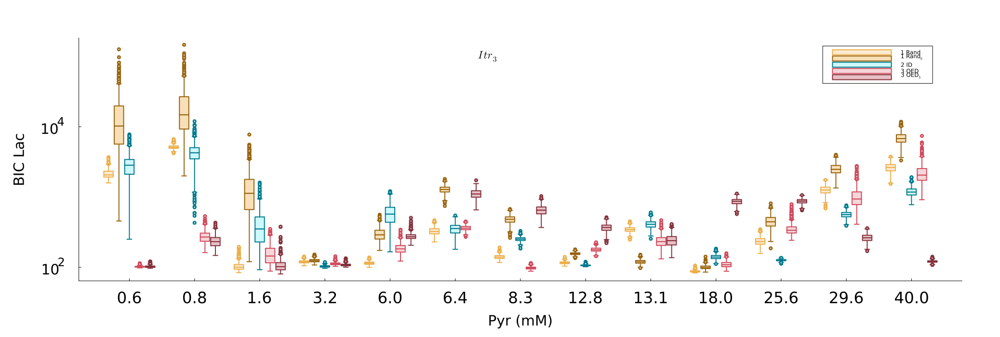

In [18]:
t = String[]
for i in 1:length(randSimsA[2][1][1:1000])
    push!(t,"1 Rand")
end
for i in 1:length(randSimsA[2][1][1:1000])
    push!(t,"1 Rand"*L"_b")
end
for i in 1:length(randSimsA[2][1][1:1000])
    push!(t,"2 ID")
end
for i in 1:length(randSimsA[2][1][1:1000])
    push!(t,"3 OED")
end
for i in 1:length(randSimsA[2][1][1:1000])
    push!(t,"3 OED"*L"_b")
end

ca = repeat(t, length(cns)-1);

Random.seed!(594584645)

xa = String[]
for j in 1:length(cns)-1
    for i in 1:length(randSimsA[i][1][1:1000])*5
        push!(xa,string(cns[j+1]))
    end
end

va2b = []
for i in 1:length(cns)-1
    ttp = vcat(BIC_Lac_R[2:end,:][:, StatsBase.sample(1:size(BIC_Lac_R1[2:end,:])[2], 1000, replace = false)][i,:], 
               BIC_Lac_Rb[2:end,:][:, StatsBase.sample(1:size(BIC_Lac_R1[2:end,:])[2], 1000, replace = false)][i,:], 
               BIC_Lac_I[2:end,:][:, StatsBase.sample(1:size(BIC_Lac_R1[2:end,:])[2], 1000, replace = false)][i,:], 
               BIC_Lac_O[2:end,:][:, StatsBase.sample(1:size(BIC_Lac_R1[2:end,:])[2], 1000, replace = false)][i,:],
               BIC_Lac_Ob[2:end,:][:, StatsBase.sample(1:size(BIC_Lac_R1[2:end,:])[2], 1000, replace = false)][i,:])
    for j in 1:length(ttp)
    push!(va2b, ttp[j])
    end
end

va2 = []
for i in 1:length(cns)-1
    ttp = vcat(nRMSE_Lac_R[2:end,:][:, StatsBase.sample(1:size(BIC_Lac_R1[2:end,:])[2], 1000, replace = false)][i,:], 
               nRMSE_Lac_Rb[2:end,:][:, StatsBase.sample(1:size(BIC_Lac_R1[2:end,:])[2], 1000, replace = false)][i,:], 
               nRMSE_Lac_I[2:end,:][:, StatsBase.sample(1:size(BIC_Lac_R1[2:end,:])[2], 1000, replace = false)][i,:], 
               nRMSE_Lac_O[2:end,:][:, StatsBase.sample(1:size(BIC_Lac_R1[2:end,:])[2], 1000, replace = false)][i,:],
               nRMSE_Lac_Ob[2:end,:][:, StatsBase.sample(1:size(BIC_Lac_R1[2:end,:])[2], 1000, replace = false)][i,:])
    for j in 1:length(ttp)
    push!(va2, ttp[j])
    end
end

ss1 = groupedboxplot(xa, va2b, group = ca, yscale=:log10, grid = false, colour = ["#faead1ff" "#f8dfb7ff" "#ccf8ffff" "#f5d6daff" "#e7c0c5ff"], ylabel = "BIC Lac", xlabel = "Pyr (mM)", 
        size = (2075,700), xtickfont=font(22), ytickfont=font(20), margins=18Plots.mm, guidefontsize = 20, markersize = 3, markerstrokewidth=2, linewidth = 2,
        markerstrokecolor = ["#edae49ff" "#97630fff" "#00798cff" "#d1495bff" "#84303bff"], linecolor = ["#edae49ff" "#97630fff" "#00798cff" "#d1495bff" "#84303bff"])
annotate!(6, 10^5,L"Itr_3", 15)

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure5Stuff\\BIC_Iter3.svg")

display(ss1)

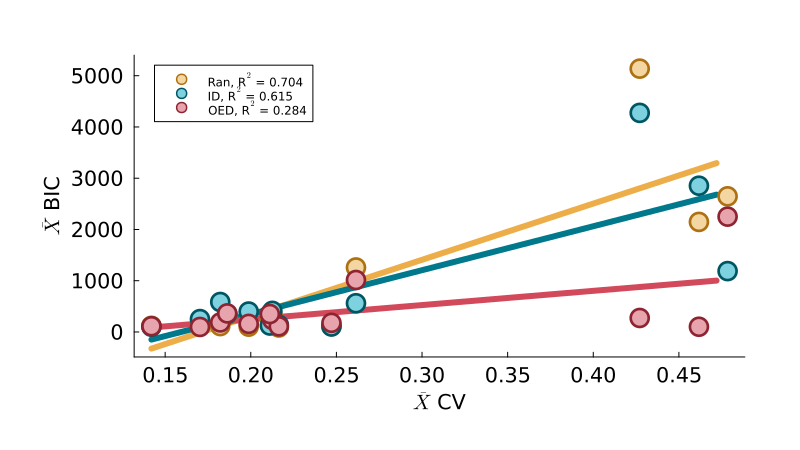

In [40]:
CVmean = [mean(CVs[i][2:end]) for i in 2:length(CVs)]
BIC_RMean = mean(BIC_Lac_R[2:end,:], dims=2)
BIC_IMean = mean(BIC_Lac_I[2:end,:], dims=2)
BIC_OMean = mean(BIC_Lac_O[2:end,:], dims=2)
BIC_FMean = mean(BIC_Lac_F[2:end,:], dims=2)


dataR = DataFrame(X=CVmean, Y=reshape(BIC_RMean, length(BIC_RMean)))
olsR = lm(@formula(Y ~ X), dataR)
dataI = DataFrame(X=CVmean, Y=reshape(BIC_IMean, length(BIC_IMean)))
olsI = lm(@formula(Y ~ X), dataI)
dataO = DataFrame(X=CVmean, Y=reshape(BIC_OMean, length(BIC_OMean)))
olsO = lm(@formula(Y ~ X), dataO)

dataF = DataFrame(X=CVmean, Y=reshape(BIC_FMean, length(BIC_FMean)))
olsF = lm(@formula(Y ~ X), dataF)


PPS = plot(collect(minimum(CVmean):0.01:maximum(CVmean)), predict(olsR, DataFrame(X = collect(minimum(CVmean):0.01:maximum(CVmean)))), color = "#edae49ff", label = "", linewidth=6, 
    size=(800,450), margin=12Plots.mm,xtickfont=font(14), 
        ytickfont=font(14), guidefont=font(14), titlefont=font(14))
    plot!(collect(minimum(CVmean):0.01:maximum(CVmean)), predict(olsI, DataFrame(X = collect(minimum(CVmean):0.01:maximum(CVmean)))), color = "#00798cff", label = "", linewidth=6)
    plot!(collect(minimum(CVmean):0.01:maximum(CVmean)), predict(olsO, DataFrame(X = collect(minimum(CVmean):0.01:maximum(CVmean)))), color = "#d1495bff", label = "", linewidth=6)

    # plot!(collect(minimum(CVmean):0.01:maximum(CVmean)), predict(olsF, DataFrame(X = collect(minimum(CVmean):0.01:maximum(CVmean)))), color = "#d1495bff", label = "", linewidth=4)

    scatter!(CVmean, BIC_RMean, label="Ran, R"*L"^2"*" = "*string(round(r2(olsR), digits = 3)), grid=false, xlabel=L"\bar{X}"*" CV", ylabel = L"\bar{X}"*" BIC", markersize=10, 
        color = "#f4d6a2ff", markerstrokecolor = "#ae7111ff", markerstrokewidth = 3)
        
    scatter!(CVmean, BIC_IMean, label="ID, R"*L"^2"*" = "*string(round(r2(olsI), digits = 3)),  markersize=10,
        color = "#7ed1deff", markerstrokecolor = "#005563ff", markerstrokewidth = 3)

    scatter!(CVmean, BIC_OMean, label="OED, R"*L"^2"*" = "*string(round(r2(olsO), digits = 3)),  markersize=10,
        color = "#e8a4adff", markerstrokecolor = "#8e2432ff", markerstrokewidth = 3 , ylim = (-487.97546937916286, 5402.008435124378))

    # scatter!(CVmean, BIC_FMean, label="Fin, R"*L"^2"*" = "*string(round(r2(olsF), digits = 3)), color = "#7a2490ff", markersize=8)


# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\SuppFig17Stuff\\CorrCvBIC.svg")

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure5Stuff\\CorrCvBIC2.svg")

display(PPS)

In [38]:
ylims(PPS)

(-487.97546937916286, 5302.008435124378)

##### Overall Summary

In [59]:
labsSA = ["Itr"*L"_2","Itr"*L"_3","Itr"*L"_3^b","Itr"*L"_2","Itr"*L"_3","Itr"*L"_2","Itr"*L"_3","Itr"*L"_3^b","Itr"*L"_4","Itr"*L"_5"]


10-element Vector{String}:
 "Itr\$_2\$"
 "Itr\$_3\$"
 "Itr\$_3^b\$"
 "Itr\$_2\$"
 "Itr\$_3\$"
 "Itr\$_2\$"
 "Itr\$_3\$"
 "Itr\$_3^b\$"
 "Itr\$_4\$"
 "Itr\$_5\$"

In [60]:
BICraw = [BIC_Lac_R1, BIC_Lac_R, BIC_Lac_Rb, BIC_Lac_I1, BIC_Lac_I, BIC_Lac_O1, BIC_Lac_O, BIC_Lac_Ob, BIC_Lac_F, BIC_Lac_F2]
nRMSEraw = [nRMSE_Lac_R1, nRMSE_Lac_R, nRMSE_Lac_Rb, nRMSE_Lac_I1, nRMSE_Lac_I, nRMSE_Lac_O1, nRMSE_Lac_O, nRMSE_Lac_Ob, nRMSE_Lac_F, nRMSE_Lac_F2]


BICs =  zeros(length(labsSA), size(BIC_Lac_F2)[1], size(BIC_Lac_F2)[2]) 
nRMSEs = zeros(length(labsSA), size(nRMSE_Lac_F2)[1], size(nRMSE_Lac_F2)[2]) 

for i in 1:length(labsSA)
    BICs[i,:,:] = BICraw[i]
    nRMSEs[i,:,:] = nRMSEraw[i]
end

BICsum = reshape(sum(BICs[:,2:end,:], dims = 2), size(BICs)[1], size(BICs)[3]);

nRMSEsum = reshape(sum(nRMSEs[:,2:end,:], dims = 2), size(nRMSEs)[1], size(nRMSEs)[3]);

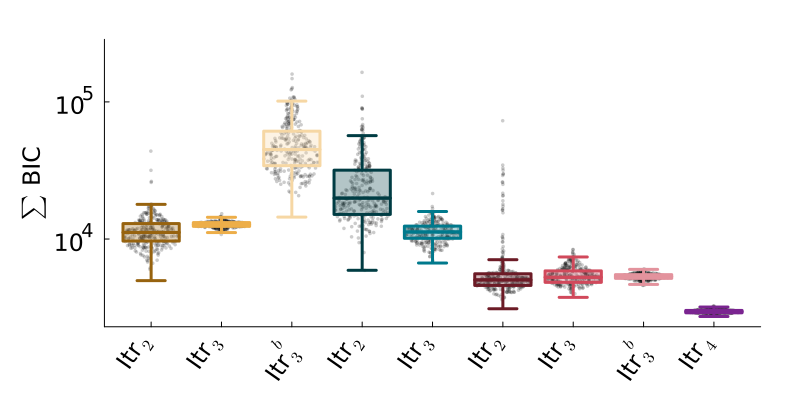

In [61]:
Random.seed!(497886468)
indsp = StatsBase.sample(1:size(BICs)[3], 300, replace = false)

ppss2 = dotplot(transpose(1:length(BICraw[1:end-1])), transpose(BICsum[1:end-1,indsp]), label = "",
        colour = "black", alpha = 0.2, markersize = 2)

boxplot!(transpose(collect(1:length(BICraw[1:end-1]))), transpose(BICsum[1:end-1,:]), yaxis=:log,
    # yerror = transpose(reshape(std(BICsum, dims = 2), length(BICraw))), #yaxis=:log,

    label = "", grid = false, xticks = (transpose([1:length(SimsAll[1:end-1])]), reshape(labsSA[1:end-1], length(labsSA[1:end-1]), 1)),
    colour = ["#97630fff" "#edae49ff" "#f6d7a4ff" "#003c43ff" "#00798cff" "#6c1b26ff" "#d1495bff" "#e3939dff" "#7a2490ff" ],
    # markercolour = ["#97630fff" "#edae49ff" "#f6d7a4ff" "#003c43ff" "#00798cff" "#6c1b26ff" "#d1495bff" "#e3939dff" "#7a2490ff" "#22862dff"],
    linecolour = ["#97630fff" "#edae49ff" "#f6d7a4ff" "#003c43ff" "#00798cff" "#6c1b26ff" "#d1495bff" "#e3939dff" "#7a2490ff" ],
    linewidth=3, markersize = 4, fillalpha=0.3, boxpoints=false,
    ylabel = L"\sum"*" BIC", xrotation =55, #ylim = (1e3, 1e5),
    size = (800,400), xtickfont=font(16), ytickfont=font(16), margins=8Plots.mm, guidefontsize = 16, markerstrokewidth=0, markeralpha  = 0)

# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\BICSum.svg")

display(ppss2)

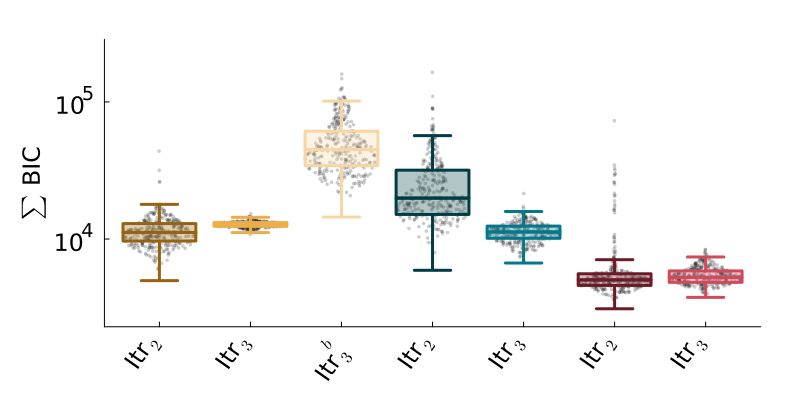

In [66]:
Random.seed!(497886468)
indsp = StatsBase.sample(1:size(BICs)[3], 300, replace = false)

ppss2 = dotplot(transpose(1:length(BICraw[1:end-3])), transpose(BICsum[1:end-3,indsp]), label = "",
        colour = "black", alpha = 0.2, markersize = 2)

boxplot!(transpose(collect(1:length(BICraw[1:end-3]))), transpose(BICsum[1:end-3,:]), yaxis=:log,
    # yerror = transpose(reshape(std(BICsum, dims = 2), length(BICraw))), #yaxis=:log,

    label = "", grid = false, xticks = (transpose([1:length(SimsAll[1:end-3])]), reshape(labsSA[1:end-3], length(labsSA[1:end-3]), 1)),
    colour = ["#97630fff" "#edae49ff" "#f6d7a4ff" "#003c43ff" "#00798cff" "#6c1b26ff" "#d1495bff" "#e3939dff" "#7a2490ff" ],
    # markercolour = ["#97630fff" "#edae49ff" "#f6d7a4ff" "#003c43ff" "#00798cff" "#6c1b26ff" "#d1495bff" "#e3939dff" "#7a2490ff" "#22862dff"],
    linecolour = ["#97630fff" "#edae49ff" "#f6d7a4ff" "#003c43ff" "#00798cff" "#6c1b26ff" "#d1495bff" "#e3939dff" "#7a2490ff" ],
    linewidth=3, markersize = 4, fillalpha=0.3, boxpoints=false,
    ylabel = L"\sum"*" BIC", xrotation =55, #ylim = (1e3, 1e5),
    size = (800,400), xtickfont=font(16), ytickfont=font(16), margins=8Plots.mm, guidefontsize = 16, markerstrokewidth=0, markeralpha  = 0)

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\BICSum2.svg")

display(ppss2)

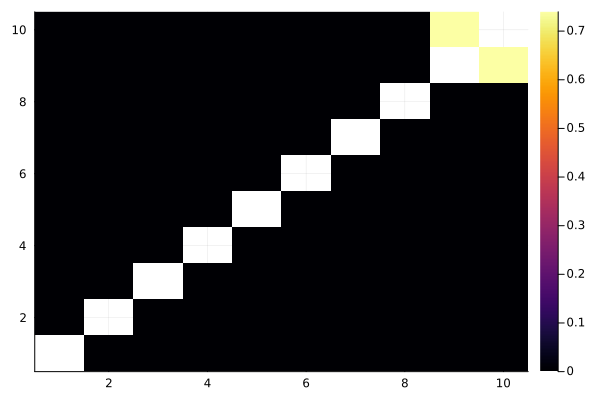

In [739]:
pvsnMR = zeros(10,10)

for i in 1:10
    for j in 1:10
        pvsnMR[i,j] = pvalue(OneSampleTTest(vec(convert.(Float64, BICsum[i,:])), vec(convert.(Float64, BICsum[j,:]))))
    end
end

heatmap(pvsnMR)

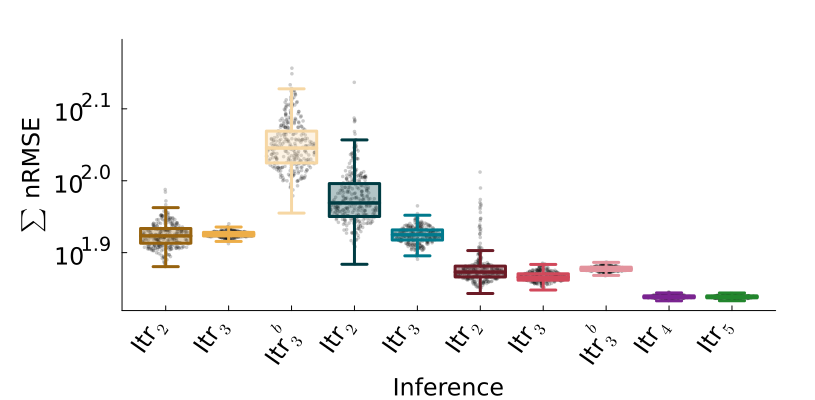

In [762]:
Random.seed!(497886468)
indsp = StatsBase.sample(1:size(nRMSEs)[3], 300, replace = false)

ppss2 = dotplot(transpose(1:length(nRMSEraw)), transpose(nRMSEsum[:,indsp]), label = "",
        colour = "black", alpha = 0.2, markersize = 2)

boxplot!(transpose(collect(1:length(nRMSEraw))), transpose(nRMSEsum), yaxis=:log,
    # yerror = transpose(reshape(std(BICsum, dims = 2), length(BICraw))), #yaxis=:log,

    label = "", grid = false, xticks = (transpose([1:length(SimsAll)]), reshape(labsSA, length(labsSA), 1)),
    colour = ["#97630fff" "#edae49ff" "#f6d7a4ff" "#003c43ff" "#00798cff" "#6c1b26ff" "#d1495bff" "#e3939dff" "#7a2490ff" "#22862dff"],
    # markercolour = ["#97630fff" "#edae49ff" "#f6d7a4ff" "#003c43ff" "#00798cff" "#6c1b26ff" "#d1495bff" "#e3939dff" "#7a2490ff" "#22862dff"],
    linecolour = ["#97630fff" "#edae49ff" "#f6d7a4ff" "#003c43ff" "#00798cff" "#6c1b26ff" "#d1495bff" "#e3939dff" "#7a2490ff" "#22862dff"],
    linewidth=3, markersize = 4, fillalpha=0.3, boxpoints=false,
    ylabel = L"\sum"*" nRMSE", xrotation =55, #ylim = (10^1.8, 10^2.2),
    size = (815,400), xtickfont=font(16), ytickfont=font(16), margins=8Plots.mm, guidefontsize = 16, markerstrokewidth=0, markeralpha  = 0, xlabel = "Inference")

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\nRMSESum.svg")

display(ppss2)

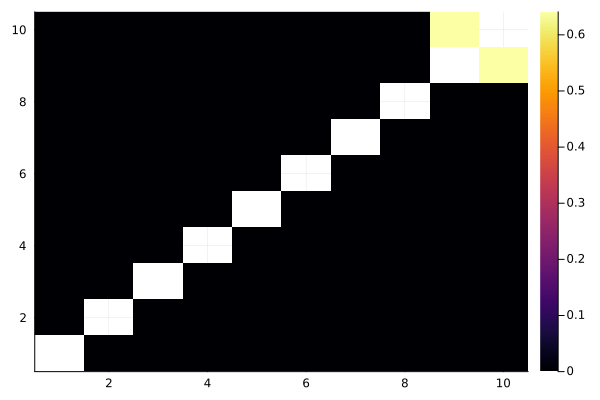

In [735]:
pvsnMR = zeros(10,10)

for i in 1:10
    for j in 1:10
        pvsnMR[i,j] = pvalue(OneSampleTTest(vec(convert.(Float64, nRMSEsum[i,:])), vec(convert.(Float64, nRMSEsum[j,:]))))
    end
end

heatmap(pvsnMR)

In [724]:
nRMSEsum

10×8000 Matrix{Float64}:
  85.8188   87.6049   86.305    83.5715  …   86.3977   81.4471   85.2453
  83.2457   83.3776   84.9677   84.1523      83.8631   83.6039   83.2032
 105.459   112.233   127.933   113.824      113.596   121.097   103.226
  99.0934   85.1464  108.918    88.3339      86.3607   89.4724   87.8404
  84.4549   83.9118   82.4306   83.5605      87.5331   83.5651   85.6227
  73.0598   97.354    73.7945   73.9133  …   72.8846   75.2866   76.8829
  71.7762   73.6925   73.6917   73.493       73.7498   74.6333   72.7391
  75.4326   76.8948   76.512    75.757       75.047    75.5833   75.285
  68.4146   69.4171   69.0361   69.3642      69.0919   68.5646   69.0544
  69.4576   69.0498   69.2531   69.3013      68.7472   69.1402   69.0879

In [422]:
println("Means \n")

br = mean(BIC_Lac_R[2:end, :], dims = 2)
bi = mean(BIC_Lac_I[2:end, :], dims = 2)
bo = mean(BIC_Lac_O[2:end, :], dims = 2)
bf = mean(BIC_Lac_F[2:end, :], dims = 2)

bsts = minimum(hcat(br, bi, bo, bf), dims = 2)

println("Rand Best = "*string(sum(bsts .== br)))
println("ID Best = "*string(sum(bsts .== bi)))
println("OED Best = "*string(sum(bsts .== bo)))
println("Final Best = "*string(sum(bsts .== bf)))

println("\n From the Validation Set \n ")

br = mean(BIC_Lac_R[[5,12].+1, :], dims = 2)
bi = mean(BIC_Lac_I[[5,12].+1, :], dims = 2)
bo = mean(BIC_Lac_O[[5,12].+1, :], dims = 2)
bf = mean(BIC_Lac_F[[5,12].+1, :], dims = 2)

bsts = minimum(hcat(br, bi, bo, bf), dims = 2)

println("Rand Best = "*string(sum(bsts .== br)))
println("ID Best = "*string(sum(bsts .== bi)))
println("OED Best = "*string(sum(bsts .== bo)))
println("Final Best = "*string(sum(bsts .== bf)))

Means 

Rand Best = 4
ID Best = 3
OED Best = 2
Final Best = 4

 From the Validation Set 
 
Rand Best = 0
ID Best = 0
OED Best = 0
Final Best = 2


In [406]:
println("STDs \n")

br = std(BIC_Lac_R[2:end, :], dims = 2)
bi = std(BIC_Lac_I[2:end, :], dims = 2)
bo = std(BIC_Lac_O[2:end, :], dims = 2)

bsts = minimum(hcat(br, bi, bo), dims = 2)

println("Rand Best = "*string(sum(bsts .== br)))
println("ID Best = "*string(sum(bsts .== bi)))
println("OED Best = "*string(sum(bsts .== bo)))

println("\n From the Validation Set \n ")

br = std(BIC_Lac_R[[5,12].+1, :], dims = 2)
bi = std(BIC_Lac_I[[5,12].+1, :], dims = 2)
bo = std(BIC_Lac_O[[5,12].+1, :], dims = 2)

bsts = minimum(hcat(br, bi, bo), dims = 2)

println("Rand Best = "*string(sum(bsts .== br)))
println("ID Best = "*string(sum(bsts .== bi)))
println("OED Best = "*string(sum(bsts .== bo)))

STDs 

Rand Best = 3
ID Best = 5
OED Best = 5

 From the Validation Set 
 
Rand Best = 0
ID Best = 1
OED Best = 1


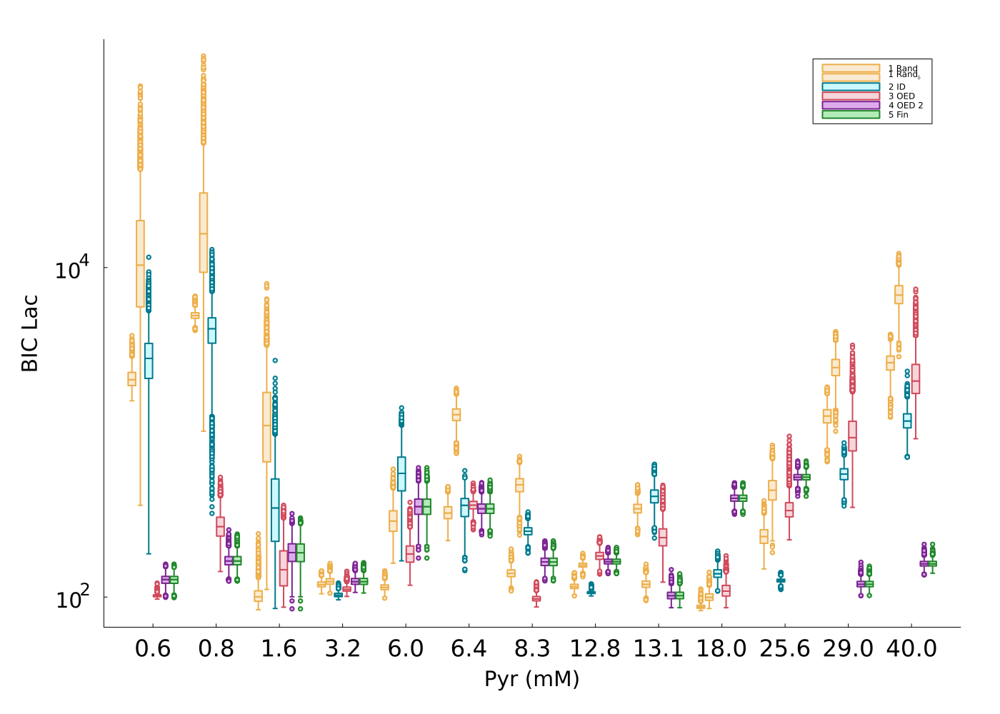

In [177]:
t = String[]
for i in 1:length(randSimsA[2][1])
    push!(t,"1 Rand")
end
for i in 1:length(randSimsA[2][1])
    push!(t,"1 Rand"*L"_b")
end
for i in 1:length(randSimsA[2][1])
    push!(t,"2 ID")
end
for i in 1:length(randSimsA[2][1])
    push!(t,"3 OED")
end
for i in 1:length(randSimsA[2][1])
    push!(t,"4 OED 2")
end
for i in 1:length(randSimsA[2][1])
    push!(t,"5 Fin")
end

ca = repeat(t, length(cns)-1);



xa = String[]
for j in 1:length(cns)-1
    for i in 1:length(randSimsA[i][1])*6
        push!(xa,string(cns[j+1]))
    end
end

va2b = []
for i in 1:length(cns)-1
    ttp = vcat(BIC_Lac_R[2:end,:][i,:], BIC_Lac_Rb[2:end,:][i,:], BIC_Lac_I[2:end,:][i,:], BIC_Lac_O[2:end,:][i,:], BIC_Lac_F[2:end,:][i,:], BIC_Lac_F2[2:end,:][i,:])
    for j in 1:length(ttp)
    push!(va2b, ttp[j])
    end
end

va2 = []
for i in 1:length(cns)-1
    ttp = vcat(nRMSE_Lac_R[2:end,:][i,:], nRMSE_Lac_Rb[2:end,:][i,:], nRMSE_Lac_I[2:end,:][i,:], nRMSE_Lac_O[2:end,:][i,:])
    for j in 1:length(ttp)
    push!(va2, ttp[j])
    end
end


ss1 = groupedboxplot(xa, va2b, group = ca, yscale=:log10, grid = false, colour = ["#faead1ff" "#faead1ff" "#ccf8ffff" "#f5d6daff" "#ddabeaff" "#b3ecb9ff"], ylabel = "BIC Lac", xlabel = "Pyr (mM)", 
        size = (1400,1000), xtickfont=font(22), ytickfont=font(20), margins=12Plots.mm, guidefontsize = 20, markersize = 3, markerstrokewidth=1, linewidth = 2,
        markerstrokecolor = ["#edae49ff" "#edae49ff" "#00798cff" "#d1495bff" "#7a2490ff" "#22862dff"], linecolor = ["#edae49ff" "#edae49ff" "#00798cff" "#d1495bff" "#7a2490ff" "#22862dff"])

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\SuppFig16Stuff\\BIC_IterFF.svg")

display(ss1)

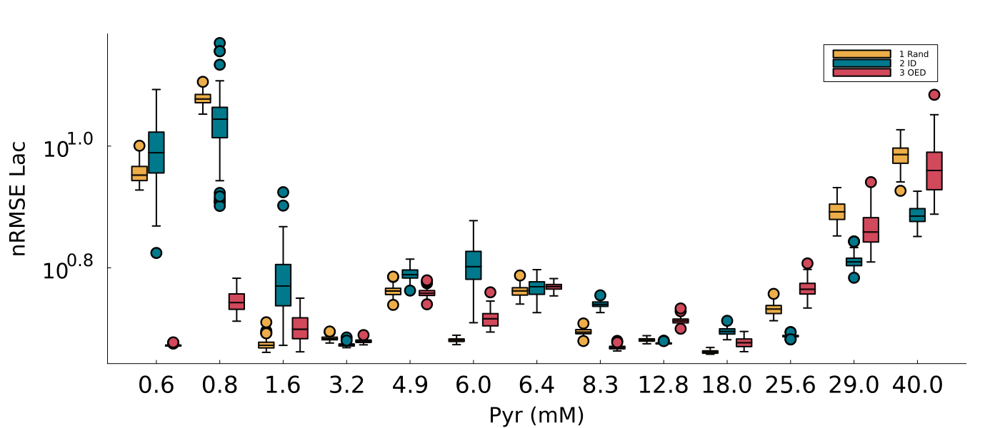

In [352]:
ss1 = groupedboxplot(xa, va2, group = ca, yscale=:log10, grid = false, colour = ["#edae49ff" "#00798cff" "#d1495bff"], ylabel = "nRMSE Lac", xlabel = "Pyr (mM)", 
        size = (1400,600), xtickfont=font(22), ytickfont=font(20), margins=10Plots.mm, guidefontsize = 20, markersize = 8, markerstrokewidth=2, linewidth = 2)

In [380]:
nr = mean(nRMSE_Lac_R[2:end, :], dims = 2)
ni = mean(nRMSE_Lac_I[2:end, :], dims = 2)
no = mean(nRMSE_Lac_O[2:end, :], dims = 2)

bsts = minimum(hcat(nr, ni, no), dims = 2)

println("Rand Best = "*string(sum(bsts .== nr)))
println("ID Best = "*string(sum(bsts .== ni)))
println("OED Best = "*string(sum(bsts .== no)))

Rand Best = 4
ID Best = 5
OED Best = 4
